#  load master files

In [1]:
import pandas as pd

PIPELINES = {
    "fluAB_illumina": "/nfs/Genomics_DEV/projects/xdong/deve/nf-fluab2/test/fluAB/results_illumina/report/master_fluAB_for_cmp.tsv",
    "fluAB_nanopore": "/nfs/Genomics_DEV/projects/xdong/deve/nf-fluab2/test/fluAB/results_nanopore/report/master_fluAB_for_cmp.tsv",
    "fluab2":         "/nfs/Genomics_DEV/projects/xdong/deve/nf-fluab2/test/results/report/master_fluab2_for_cmp.tsv",
}

frames = {}
for name, path in PIPELINES.items():
    df = pd.read_csv(path, sep="\t", dtype=str)
    df["pipeline"] = name
    frames[name] = df
    print(f"{name:16s} {df.shape[0]:4d} rows, {df.shape[1]:3d} columns")

# Concatenate the two fluAB platforms into a single fluAB frame.
fluAB_df = pd.concat(
    [frames["fluAB_illumina"], frames["fluAB_nanopore"]],
    ignore_index=True,
)
fluab2_df = frames["fluab2"]

print(f"\nfluAB (combined): {fluAB_df.shape[0]} rows, {fluAB_df.shape[1]} columns")
print(f"fluab2:           {fluab2_df.shape[0]} rows, {fluab2_df.shape[1]} columns")

# Sanity check: platform split within fluAB, and no overlap with fluab2.
print("\nfluAB rows per pipeline:")
print(fluAB_df.groupby("pipeline")["sample"].nunique().to_string())

print("\nfluab2 samples:")
print(fluab2_df["sample"].nunique())

# Confirm column sets match after concatenation.
missing = set(fluAB_df.columns) - set(fluab2_df.columns)
extra = set(fluab2_df.columns) - set(fluAB_df.columns)
if missing:
    print(f"\ncolumns only in fluAB: {sorted(missing)}")
if extra:
    print(f"columns only in fluab2: {sorted(extra)}")

fluAB_illumina      9 rows,  82 columns
fluAB_nanopore      2 rows,  82 columns
fluab2             10 rows,  82 columns

fluAB (combined): 11 rows, 82 columns
fluab2:           10 rows, 82 columns

fluAB rows per pipeline:
pipeline
fluAB_illumina    6
fluAB_nanopore    2

fluab2 samples:
8


In [2]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 40)

for name, df in frames.items():
    print("=" * 30, name, "=" * 30)
    print(f"shape: {df.shape}")
    print(df.head(3).to_string(index=False))
    print()

============================== fluAB_illumina ==============================
shape: (9, 82)
     sample read_type input_num_reads input_total_bases input_avg_len trimmed_num_reads trimmed_total_bases trimmed_avg_len trimmed_pct dehosted_num_reads dehosted_total_bases dehosted_avg_len dehosted_pct_of_trimmed dehosted_pct_of_input ref_subtype_index ref_subtype predicted_type_or_lineage               seg1_id seg1_length seg1_numreads seg1_completeness seg1_meandepth               seg2_id seg2_length seg2_numreads seg2_completeness seg2_meandepth               seg3_id seg3_length seg3_numreads seg3_completeness seg3_meandepth               seg4_id seg4_length seg4_numreads seg4_completeness seg4_meandepth seg4_typing seg4_typing_pident seg4_typing_qcov seg4_typing_evalue seg4_clade seg4_proposedSubclade seg4_subclade seg4_nextclade_qc.overallStatus               seg5_id seg5_length seg5_numreads seg5_completeness seg5_meandepth               seg6_id seg6_length seg6_numreads seg6_completen

In [3]:


READ_QC_COLUMNS = [
    "read_type",
    "input_num_reads", "input_total_bases", "input_avg_len",
    "trimmed_num_reads", "trimmed_total_bases", "trimmed_avg_len", "trimmed_pct",
    "dehosted_num_reads", "dehosted_total_bases", "dehosted_avg_len",
    "dehosted_pct_of_trimmed", "dehosted_pct_of_input",
]

READ_QC_COLUMNS_PLOT = [
    c for c in READ_QC_COLUMNS
    if not c.startswith("input_")
    and "_pct" not in c
]

CATEGORICAL_COLUMNS = {"read_type"}
MASTER_KEY = ["sample", "ref_subtype"]


def read_qc_delta_wide(m1, m2, columns=READ_QC_COLUMNS_PLOT,
                       key=MASTER_KEY, name1="fluAB", name2="fluab2"):
    columns = [c for c in columns
               if c not in CATEGORICAL_COLUMNS
               and (c in m1.columns or c in m2.columns)]

    def prep(df):
        d = df[[*key, *[c for c in columns if c in df.columns]]].copy()
        d = d.rename(columns={key[0]: "sample", key[1]: "ref_subtype"})
        return d.drop_duplicates(subset=["sample"], keep="first").set_index("sample")

    a, b = prep(m1), prep(m2)
    common = a.index.intersection(b.index)

    out = pd.DataFrame(index=common)
    for c in columns:
        av = pd.to_numeric(a.loc[common, c], errors="coerce") if c in a.columns else pd.Series(pd.NA, index=common)
        bv = pd.to_numeric(b.loc[common, c], errors="coerce") if c in b.columns else pd.Series(pd.NA, index=common)
        out[f"{c}_{name1}"] = av
        out[f"{c}_{name2}"] = bv
        out[f"{c}_delta"] = bv - av

    return out.round(2)


# ---- Display ----

wide = read_qc_delta_wide(fluAB_df, fluab2_df)
wide = wide.sort_index()   # alphabetical by sample

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 400)
pd.set_option("display.max_rows", 100)

print("=" * 100)
print("Read QC delta — wide form (one row per sample, sorted by sample)")
print("  each metric appears 3×: fluAB value, fluab2 value, delta = fluab2 − fluAB")
print("=" * 100)
display(wide)

Read QC delta — wide form (one row per sample, sorted by sample)
  each metric appears 3×: fluAB value, fluab2 value, delta = fluab2 − fluAB


,trimmed_num_reads_fluAB,trimmed_num_reads_fluab2,trimmed_num_reads_delta,trimmed_total_bases_fluAB,trimmed_total_bases_fluab2,trimmed_total_bases_delta,trimmed_avg_len_fluAB,trimmed_avg_len_fluab2,trimmed_avg_len_delta,dehosted_num_reads_fluAB,dehosted_num_reads_fluab2,dehosted_num_reads_delta,dehosted_total_bases_fluAB,dehosted_total_bases_fluab2,dehosted_total_bases_delta,dehosted_avg_len_fluAB,dehosted_avg_len_fluab2,dehosted_avg_len_delta
sample,,,,,,,,,,,,,,,,,,
flua_i_1,127474,127379,-95,35203817,35180904,-22913,138.1,138.1,0.0,127367,127249,-118,35174937,35144093,-30844,138.1,138.1,0.0
flua_i_2,120733,120613,-120,33385125,33350786,-34339,138.3,138.3,0.0,108017,107687,-330,30040969,29929597,-111372,139.1,139.0,-0.1
flua_i_3_co,85000,84931,-69,23019014,22998473,-20541,135.4,135.4,0.0,64366,64091,-275,17731365,17620016,-111349,137.7,137.5,-0.2
flua_i_4_co,41926,41883,-43,11691301,11679176,-12125,139.4,139.4,0.0,34724,34345,-379,9734886,9624901,-109985,140.2,140.1,-0.1
flua_n_1,41816,40057,-1759,37113522,34537477,-2576045,887.5,862.2,-25.3,41615,39935,-1680,36931040,34452369,-2478671,887.4,862.7,-24.7
flua_n_2,33450,34314,864,37866232,37277199,-589033,1132.0,1086.4,-45.6,30232,31788,1556,35506597,35544526,37929,1174.5,1118.2,-56.3
flub_i_1,151282,151107,-175,41803351,41757114,-46237,138.2,138.2,0.0,51951,51899,-52,14347427,14243383,-104044,138.1,137.2,-0.9
flub_i_2,166896,166725,-171,45163680,45117352,-46328,135.3,135.3,0.0,166895,166724,-171,45163518,45117100,-46418,135.3,135.3,0.0


# read qc visualization

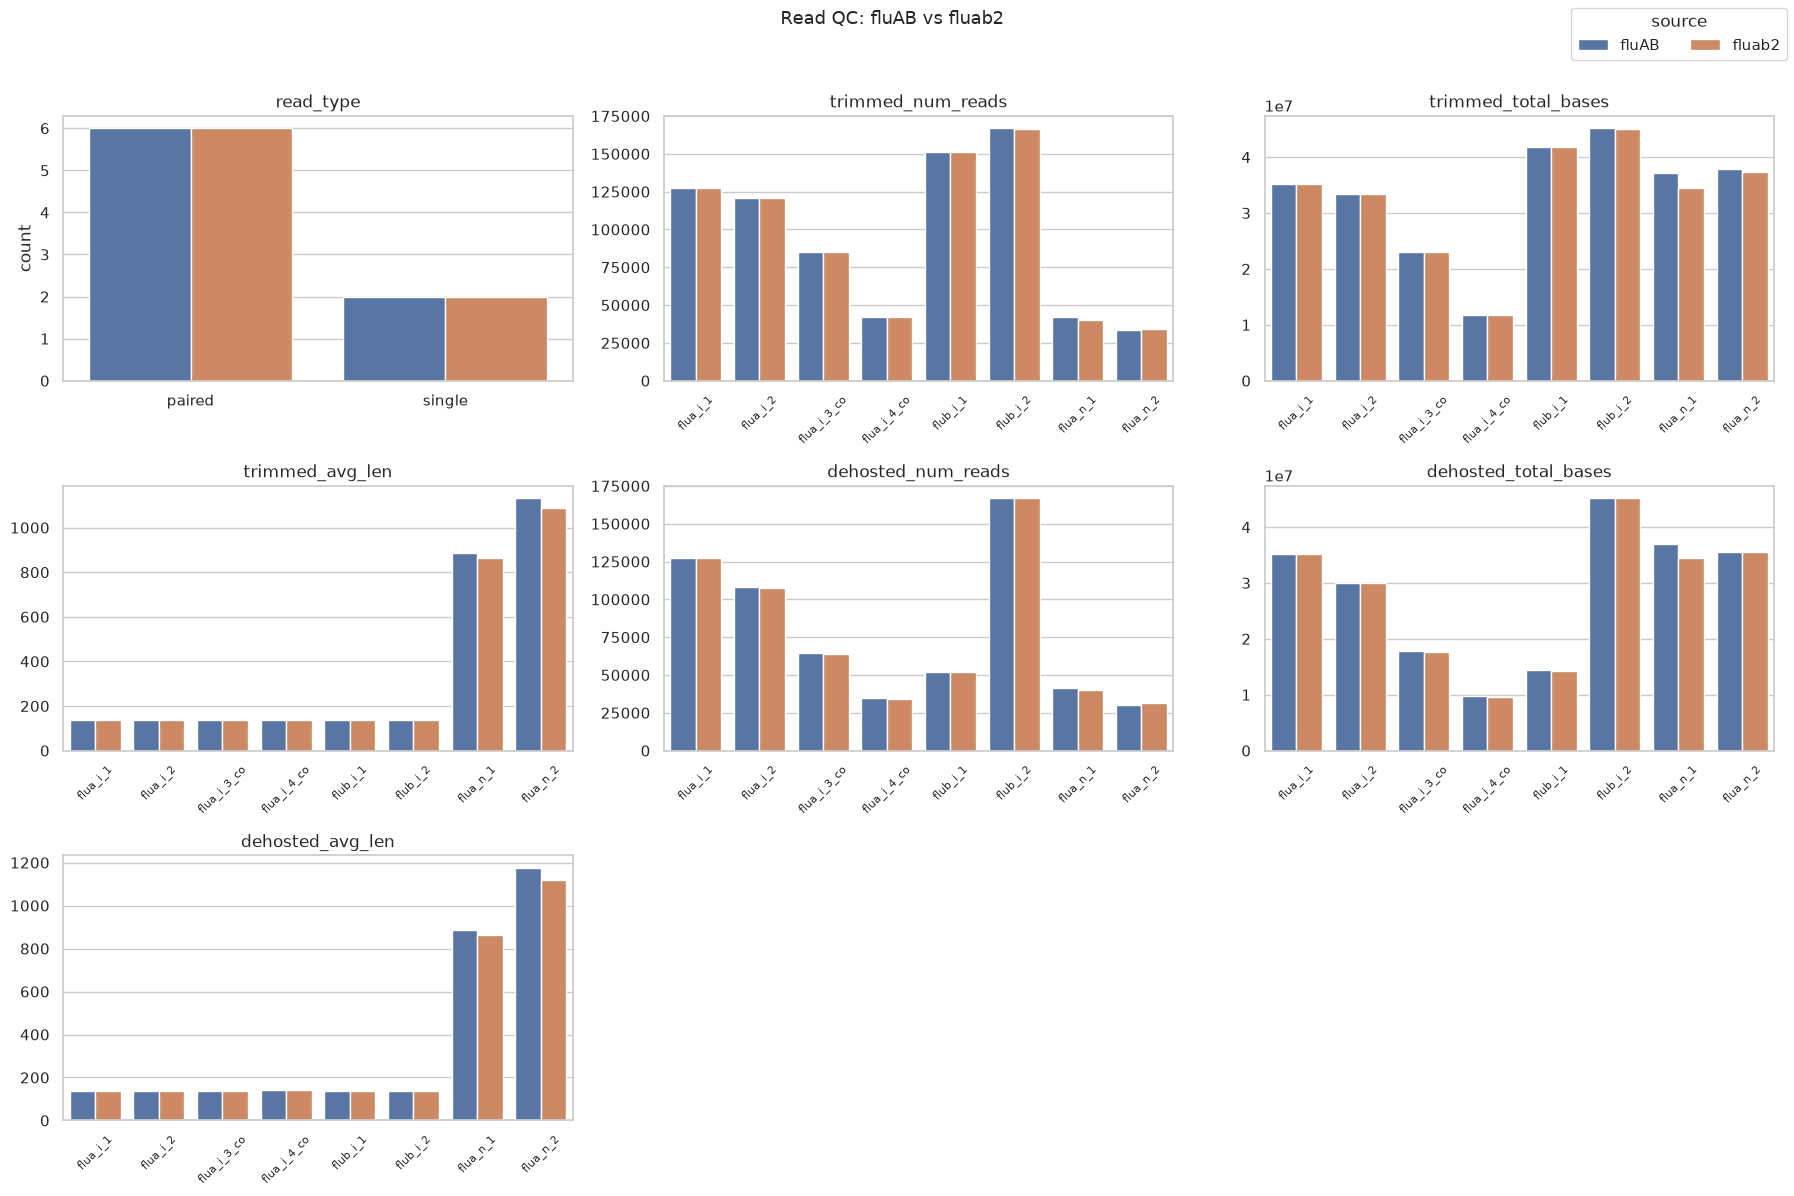

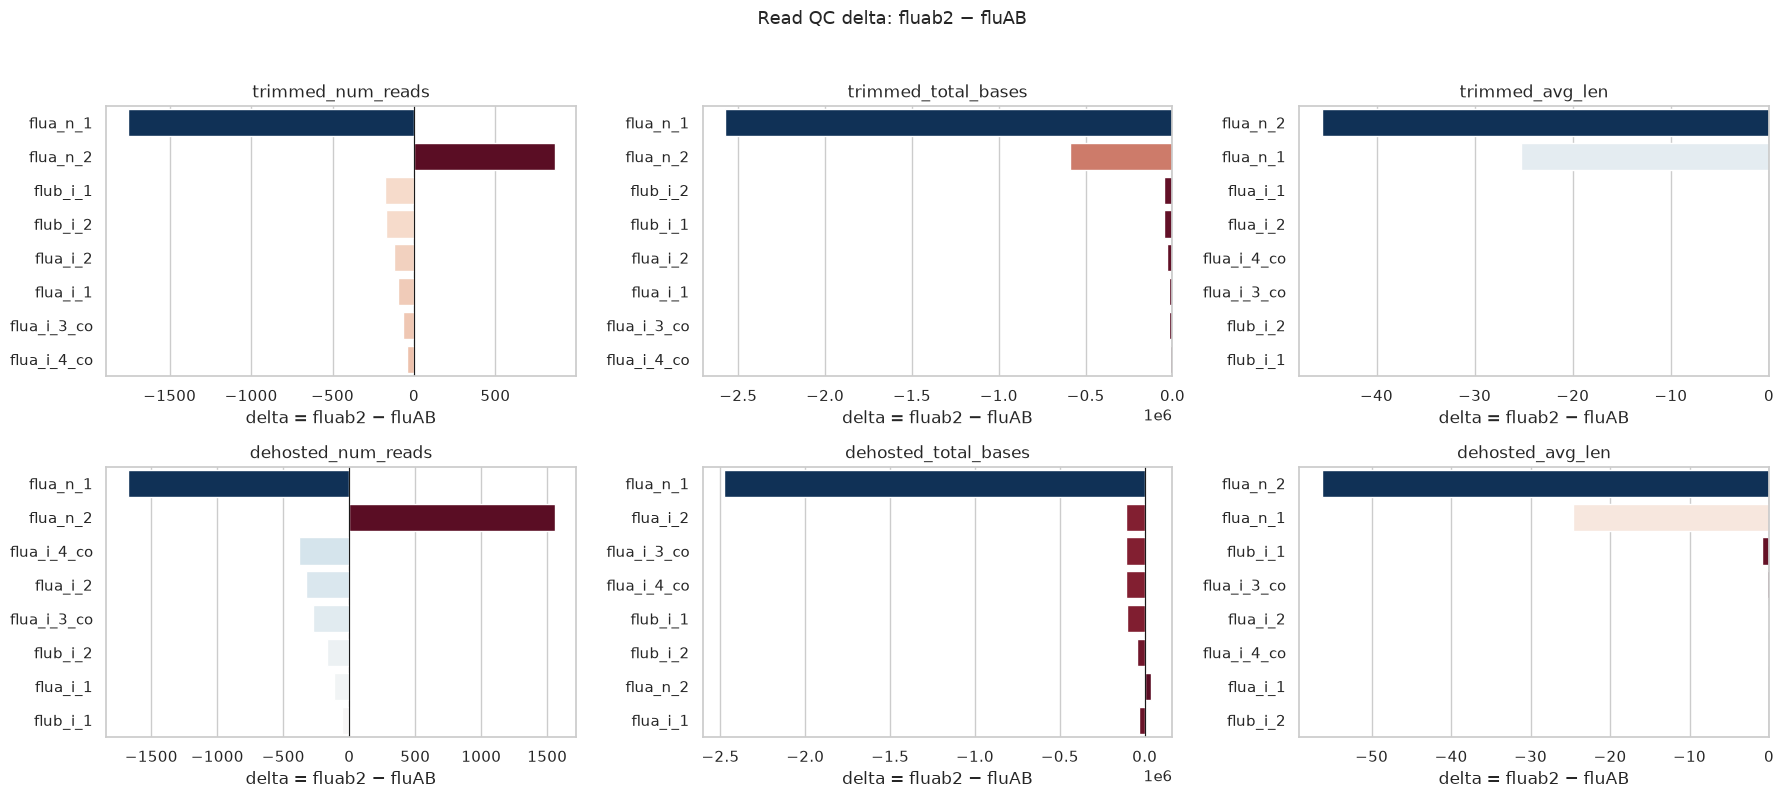

In [4]:
%matplotlib inline

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

READ_QC_COLUMNS = [
    "read_type",
    "input_num_reads", "input_total_bases", "input_avg_len",
    "trimmed_num_reads", "trimmed_total_bases", "trimmed_avg_len", "trimmed_pct",
    "dehosted_num_reads", "dehosted_total_bases", "dehosted_avg_len",
    "dehosted_pct_of_trimmed", "dehosted_pct_of_input",
]

READ_QC_COLUMNS_PLOT = [
    c for c in READ_QC_COLUMNS
    if not c.startswith("input_")
    and "_pct" not in c
]

CATEGORICAL_COLUMNS = {"read_type"}


def plot_read_qc(m1, m2, columns, key=("sample", "ref_subtype"),
                 name1="fluAB", name2="fluab2", max_samples=None):
    """
    One panel per read-QC metric, fluAB vs fluab2 bars per
    sample. Read QC is per-sample, so duplicate rows for the
    same sample (co-infections) are collapsed to one row.
    """
    palette = {name1: "#4c72b0", name2: "#dd8452"}
    columns = [c for c in columns if c in m1.columns or c in m2.columns]
    if not columns:
        print("No requested columns present.")
        return None

    def prep(df, source):
        cols = [c for c in key if c in df.columns]
        cols += [c for c in columns if c in df.columns and c not in cols]
        d = df[cols].copy()
        d = d.rename(columns={key[0]: "sample", key[1]: "ref_subtype"})
        d = d.drop_duplicates(subset=["sample"], keep="first")
        d["source"] = source
        return d

    long = pd.concat([prep(m1, name1), prep(m2, name2)], ignore_index=True)
    long["sample"] = long["sample"].fillna("NA")
    if max_samples:
        keep = long["sample"].drop_duplicates().head(max_samples)
        long = long[long["sample"].isin(keep)]

    long = long.melt(
        id_vars=["sample", "source"],
        value_vars=[c for c in columns if c in long.columns],
        var_name="metric", value_name="value",
    )

    n_cols, n_rows = 3, (len(columns) + 2) // 3
    fig, axes = plt.subplots(n_rows, n_cols,
                             figsize=(6 * n_cols, 4 * n_rows),
                             squeeze=False)
    legend_handles = []

    for ax, column in zip(axes.flat, columns):
        sub = long[long["metric"] == column].copy()

        if column in CATEGORICAL_COLUMNS:
            sub["value"] = sub["value"].fillna("NA")
            sub = sub[sub["value"] != ""]
            if sub.empty:
                ax.set_title(f"{column} (no data)")
                continue
            sns.countplot(data=sub, x="value", hue="source",
                          palette=palette, ax=ax)
            ax.set_xlabel("")
            ax.set_ylabel("count")
        else:
            sub["value"] = pd.to_numeric(sub["value"], errors="coerce")
            sub = sub.dropna(subset=["value"])
            if sub.empty:
                ax.set_title(f"{column} (no numeric data)")
                continue
            sns.barplot(data=sub, x="sample", y="value", hue="source",
                        palette=palette, ax=ax)
            ax.set_xlabel("")
            ax.set_ylabel("")
            ax.tick_params(axis="x", rotation=45, labelsize=8)

        ax.set_title(column)
        handles, labels = ax.get_legend_handles_labels()
        if handles and not legend_handles:
            legend_handles = handles
        leg = ax.get_legend()
        if leg is not None:
            leg.remove()

    for ax in axes.flat[len(columns):]:
        ax.set_visible(False)

    if legend_handles:
        fig.legend(legend_handles, [name1, name2],
                   loc="upper right", title="source", ncol=2, frameon=True)

    fig.suptitle(f"Read QC: {name1} vs {name2}", fontsize=13, y=0.995)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()
    return fig


def plot_read_qc_delta(m1, m2, columns, key=("sample", "ref_subtype"),
                       name1="fluAB", name2="fluab2"):
    """
    Signed delta (name2 − name1) per sample, one panel per
    numeric read-QC metric.
    """
    columns = [c for c in columns
               if c not in CATEGORICAL_COLUMNS
               and (c in m1.columns or c in m2.columns)]

    def prep(df):
        d = df[[*key, *[c for c in columns if c in df.columns]]].copy()
        d = d.rename(columns={key[0]: "sample", key[1]: "ref_subtype"})
        return d.drop_duplicates(subset=["sample"], keep="first").set_index("sample")

    a, b = prep(m1), prep(m2)
    common = a.index.intersection(b.index)

    n_cols, n_rows = 3, (len(columns) + 2) // 3
    fig, axes = plt.subplots(n_rows, n_cols,
                             figsize=(6 * n_cols, 4 * n_rows),
                             squeeze=False)

    for ax, column in zip(axes.flat, columns):
        if column not in a.columns or column not in b.columns:
            ax.set_title(f"{column} (missing)")
            continue
        av = pd.to_numeric(a.loc[common, column], errors="coerce")
        bv = pd.to_numeric(b.loc[common, column], errors="coerce")
        delta = (bv - av).dropna()
        if delta.empty:
            ax.set_title(f"{column} (no numeric data)")
            continue
        sub = pd.DataFrame({
            "sample": delta.index,
            "delta": delta.values,
        }).sort_values("delta", key=abs, ascending=False)
        sns.barplot(data=sub, x="delta", y="sample",
                    hue="delta", palette="RdBu_r", dodge=False, ax=ax)
        ax.axvline(0, color="k", linewidth=0.8)
        ax.set_xlabel(f"delta = {name2} − {name1}")
        ax.set_ylabel("")
        ax.set_title(column)
        ax.legend().remove()

    for ax in axes.flat[len(columns):]:
        ax.set_visible(False)

    fig.suptitle(f"Read QC delta: {name2} − {name1}", fontsize=13, y=0.995)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()
    return fig


# ---- Render (exactly two figures) ----

fig_qc = plot_read_qc(fluAB_df, fluab2_df, READ_QC_COLUMNS_PLOT)
fig_delta = plot_read_qc_delta(fluAB_df, fluab2_df, READ_QC_COLUMNS_PLOT)

# Consensus stats

flua_i_3_co:

* segment1: H3N2 is missing from fluAB but showed in fluab2.  I trace back, fluAB did not have any segment 1 identified from dataabse for H3N2 althought the mash screen commnad is the same, fluAB even with loose parameter
* segment2: 
    * H1N1 is missing from fluab2 but show up in fluaAB, seekref filtered the seg2 ref out beucase the aboundance is only 5 and in fluAB, there is a decent hits for H1N2 segment 2
    * H3N2 is missing from fluAB
* segment3:
    * H1N1 is missing from fluab2 and show up in fluAB
* segment 5:
    * H1N1 is missing from fluab2 and show up in fluAB
    * H3N2 show in fluab2 but missing from fluAB
* segment7: 
    * H3N2 in fluAB but missing from fluab2

flub_i_2:

* segment5: both pipeline get good assembly but the typing is different. the ref subtype of fluab2 is yamagata but is victorial for fluAB. When I checked segment 4 typing, it is yamagat 

segment 4: 
* segment 4 is shorter for a few samples flua_i_1 H3N2 and flua_n_9 H3N2 and fluab fixed the problems



In [11]:
import pandas as pd

MASTER_KEY = ["sample", "ref_subtype"]
SEGMENTS = ("1", "2", "3", "4", "5", "6", "7", "8")
SEGMENT_METRICS = ["length", "completeness", "meandepth"]


def coinfection_table(
    m1, m2, name1="fluAB", name2="fluab2",
    segments=SEGMENTS, metrics=SEGMENT_METRICS,
    key=MASTER_KEY,
):
    """
    Table for co-infected samples: one row per
    (sample, ref_subtype), one column per (segment, metric),
    with name1 / name2 values and a delta.

    Columns are ordered:
        sample, ref_subtype,
        seg1 length (name1), seg1 length (name2), seg1 length Δ,
        seg1 completeness ..., seg1 meandepth ...,
        seg2 length ..., ...

    Rows are sorted by sample then ref_subtype.
    """
    coinfected = find_coinfected_samples(m1, m2, key)
    if not coinfected:
        print("No co-infected samples found in either frame.")
        return None

    def prep(df):
        d = df.copy()
        d["sample"] = d["sample"].astype(str)
        d["ref_subtype"] = d["ref_subtype"].astype(str)
        return d[
            (d["sample"].isin(coinfected))
            & d[["sample", "ref_subtype"]].notna().all(axis=1)
        ].copy()

    a = prep(m1)
    b = prep(m2)

    # Merge on the key, so a row that only exists in one
    # pipeline shows NaN on the missing side.
    merged = a.merge(
        b,
        on=key,
        how="outer",
        suffixes=(f"_{name1}", f"_{name2}"),
    )

    # Build the display frame column by column, so we control
    # the order: segment-major, metric-minor, value1/value2/delta.
    out = merged[key].copy()
    for seg in segments:
        for met in metrics:
            c1 = f"seg{seg}_{met}_{name1}"
            c2 = f"seg{seg}_{met}_{name2}"
            v1 = pd.to_numeric(merged.get(c1), errors="coerce")
            v2 = pd.to_numeric(merged.get(c2), errors="coerce")
            out[f"seg{seg} {met} ({name1})"] = v1
            out[f"seg{seg} {met} ({name2})"] = v2
            out[f"seg{seg} {met} Δ"] = (v2 - v1).round(2)

    out = out.sort_values(key).reset_index(drop=True)

    # Round numeric columns for display.
    for c in out.columns:
        if out[c].dtype.kind in "fc":
            out[c] = out[c].round(2)

    return out


# ---- Display ----

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 400)
pd.set_option("display.max_rows", 100)

co_table = coinfection_table(fluAB_df, fluab2_df)

if co_table is not None:
    print("=" * 100)
    print(f"Co-infection coverage table: {name1 if (name1 := 'fluAB') else ''} vs fluab2")
    print("  one row per (sample, ref_subtype); "
          "each metric appears as fluAB / fluab2 / delta")
    print("=" * 100)
    display(co_table)

Co-infection coverage table: fluAB vs fluab2
  one row per (sample, ref_subtype); each metric appears as fluAB / fluab2 / delta


,sample,ref_subtype,seg1 length (fluAB),seg1 length (fluab2),seg1 length Δ,seg1 completeness (fluAB),seg1 completeness (fluab2),seg1 completeness Δ,seg1 meandepth (fluAB),seg1 meandepth (fluab2),seg1 meandepth Δ,seg2 length (fluAB),seg2 length (fluab2),seg2 length Δ,seg2 completeness (fluAB),seg2 completeness (fluab2),seg2 completeness Δ,seg2 meandepth (fluAB),seg2 meandepth (fluab2),seg2 meandepth Δ,seg3 length (fluAB),seg3 length (fluab2),seg3 length Δ,seg3 completeness (fluAB),seg3 completeness (fluab2),seg3 completeness Δ,seg3 meandepth (fluAB),seg3 meandepth (fluab2),seg3 meandepth Δ,seg4 length (fluAB),seg4 length (fluab2),seg4 length Δ,seg4 completeness (fluAB),seg4 completeness (fluab2),seg4 completeness Δ,seg4 meandepth (fluAB),seg4 meandepth (fluab2),seg4 meandepth Δ,seg5 length (fluAB),seg5 length (fluab2),seg5 length Δ,seg5 completeness (fluAB),seg5 completeness (fluab2),seg5 completeness Δ,seg5 meandepth (fluAB),seg5 meandepth (fluab2),seg5 meandepth Δ,seg6 length (fluAB),seg6 length (fluab2),seg6 length Δ,seg6 completeness (fluAB),seg6 completeness (fluab2),seg6 completeness Δ,seg6 meandepth (fluAB),seg6 meandepth (fluab2),seg6 meandepth Δ,seg7 length (fluAB),seg7 length (fluab2),seg7 length Δ,seg7 completeness (fluAB),seg7 completeness (fluab2),seg7 completeness Δ,seg7 meandepth (fluAB),seg7 meandepth (fluab2),seg7 meandepth Δ,seg8 length (fluAB),seg8 length (fluab2),seg8 length Δ,seg8 completeness (fluAB),seg8 completeness (fluab2),seg8 completeness Δ,seg8 meandepth (fluAB),seg8 meandepth (fluab2),seg8 meandepth Δ
0,flua_i_3_co,H1N1,2280.0,2280.0,0.0,100.00,100.00,0.00,385.74,97.03,-288.71,2274.0,NaN,NaN,100.0,NaN,NaN,113.60,NaN,NaN,2124.0,NaN,NaN,98.82,NaN,NaN,45.12,NaN,NaN,1701.0,1701.0,0.0,100.0,100.00,0.00,330.38,324.37,-6.01,1497.0,NaN,NaN,100.00,NaN,NaN,194.38,NaN,NaN,1410.0,1410.0,0.0,99.79,100.00,0.21,1127.92,1131.43,3.51,982.0,982.0,0.0,100.0,96.74,-3.26,6924.91,8599.91,1675.00,838.0,838.0,0.0,100.0,100.0,0.0,1399.91,1331.50,-68.41
1,flua_i_3_co,H3N2,NaN,2280.0,NaN,NaN,100.00,NaN,NaN,354.67,NaN,NaN,2274.0,NaN,NaN,98.33,NaN,NaN,109.87,NaN,2151.0,2151.0,0.0,100.00,95.07,-4.93,276.64,207.07,-69.57,1701.0,1701.0,0.0,100.0,100.00,0.00,77.71,77.63,-0.08,NaN,1497.0,NaN,NaN,98.40,NaN,NaN,230.92,NaN,1410.0,1410.0,0.0,100.00,100.00,0.00,176.53,176.46,-0.06,982.0,NaN,NaN,100.0,NaN,NaN,3839.04,NaN,NaN,838.0,838.0,0.0,100.0,100.0,0.0,464.39,466.38,1.99
2,flua_i_4_co,H1N1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1497.0,1497.0,0.0,99.67,99.27,-0.4,56.25,21.27,-34.98,1410.0,1410.0,0.0,92.06,87.16,-4.90,16.46,16.20,-0.26,982.0,982.0,0.0,99.8,100.00,0.20,995.85,1179.67,183.82,838.0,838.0,0.0,100.0,100.0,0.0,578.88,576.03,-2.85
3,flua_i_4_co,H3N2,2280.0,2280.0,0.0,100.00,100.00,0.00,445.94,449.05,3.10,2277.0,2277.0,0.0,100.0,100.00,0.00,136.29,130.43,-5.86,2151.0,2151.0,0.0,100.00,100.00,0.00,302.60,285.75,-16.86,1701.0,1701.0,0.0,100.0,100.00,0.00,260.55,260.33,-0.22,1497.0,1497.0,0.0,100.00,100.00,0.0,466.77,502.68,35.91,1410.0,1410.0,0.0,99.86,100.00,0.14,398.27,399.21,0.94,982.0,982.0,0.0,100.0,100.00,0.00,3114.94,2981.52,-133.42,838.0,838.0,0.0,100.0,100.0,0.0,934.70,892.14,-42.56
4,flub_i_2,Victoria,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1683.0,NaN,NaN,100.00,NaN,NaN,3329.82,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,flub_i_2,Yamagata,2313.0,2259.0,-54.0,96.02,99.91,3.89,1695.44,1303.77,-391.67,2259.0,2313.0,54.0,100.0,95.89,-4.11,1308.80,1689.58,380.78,2181.0,2181.0,0.0,100.00,100.00,0.00,333.71,291.98,-41.73,1755.0,1755.0,0.0,100.0,99.94,-0.06,2616.76,2609.66,-7.10,NaN,1683.0,NaN,NaN,99.94,NaN,NaN,3270.58,NaN,1401.0,1408.0,7.0,100.00,100.00,0.00,2097.85,2054.74,-43.11,747.0,1076.0,329.0,100.0,94.80,-5.20,11954.90,13411.90,1457.00,1024.

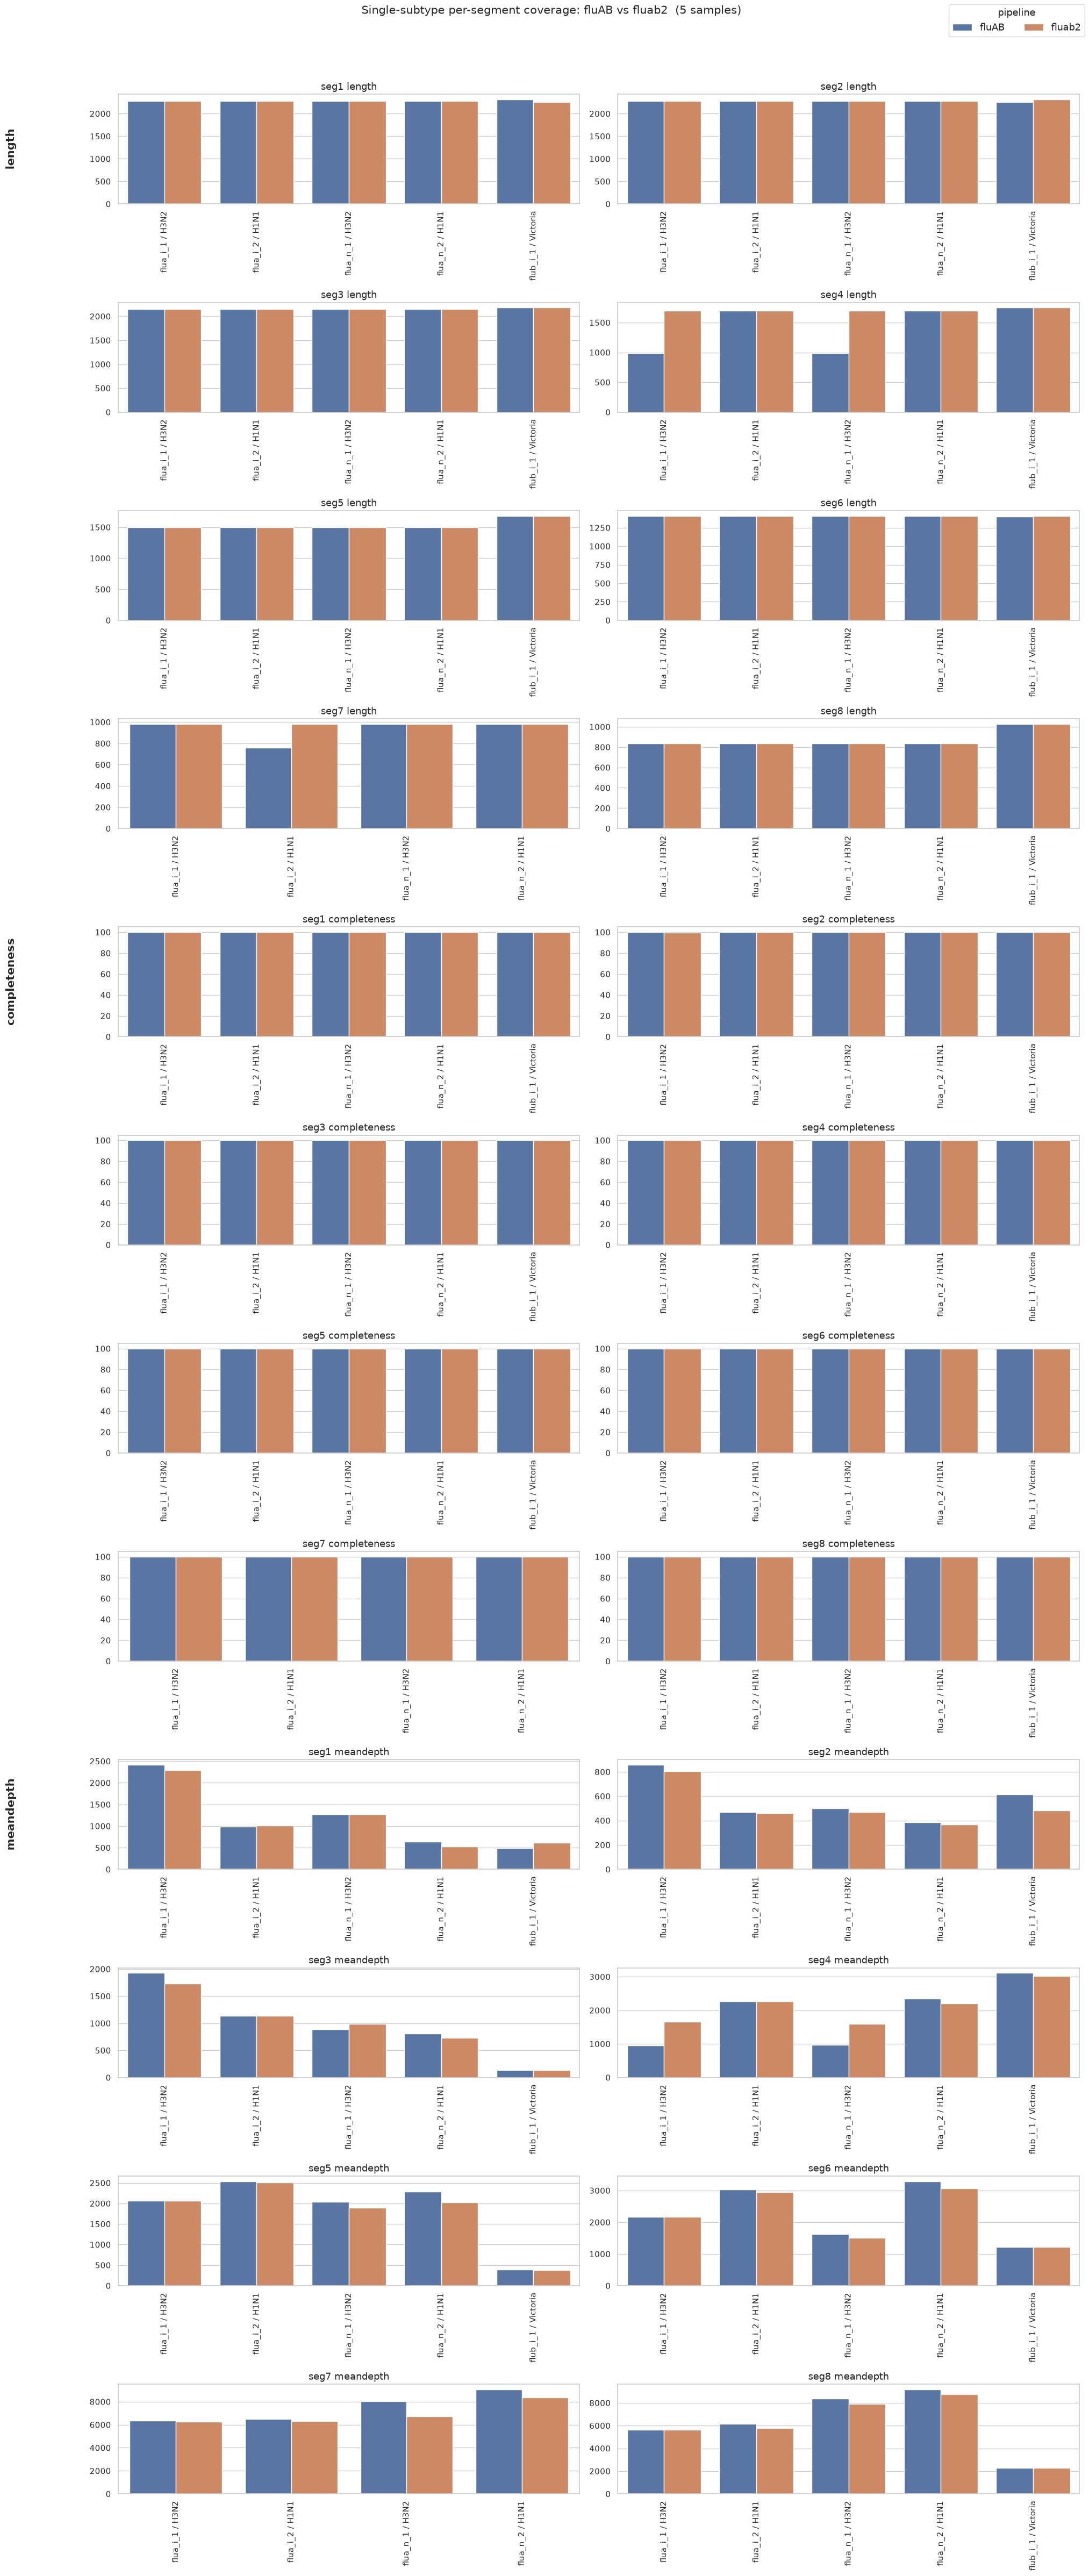

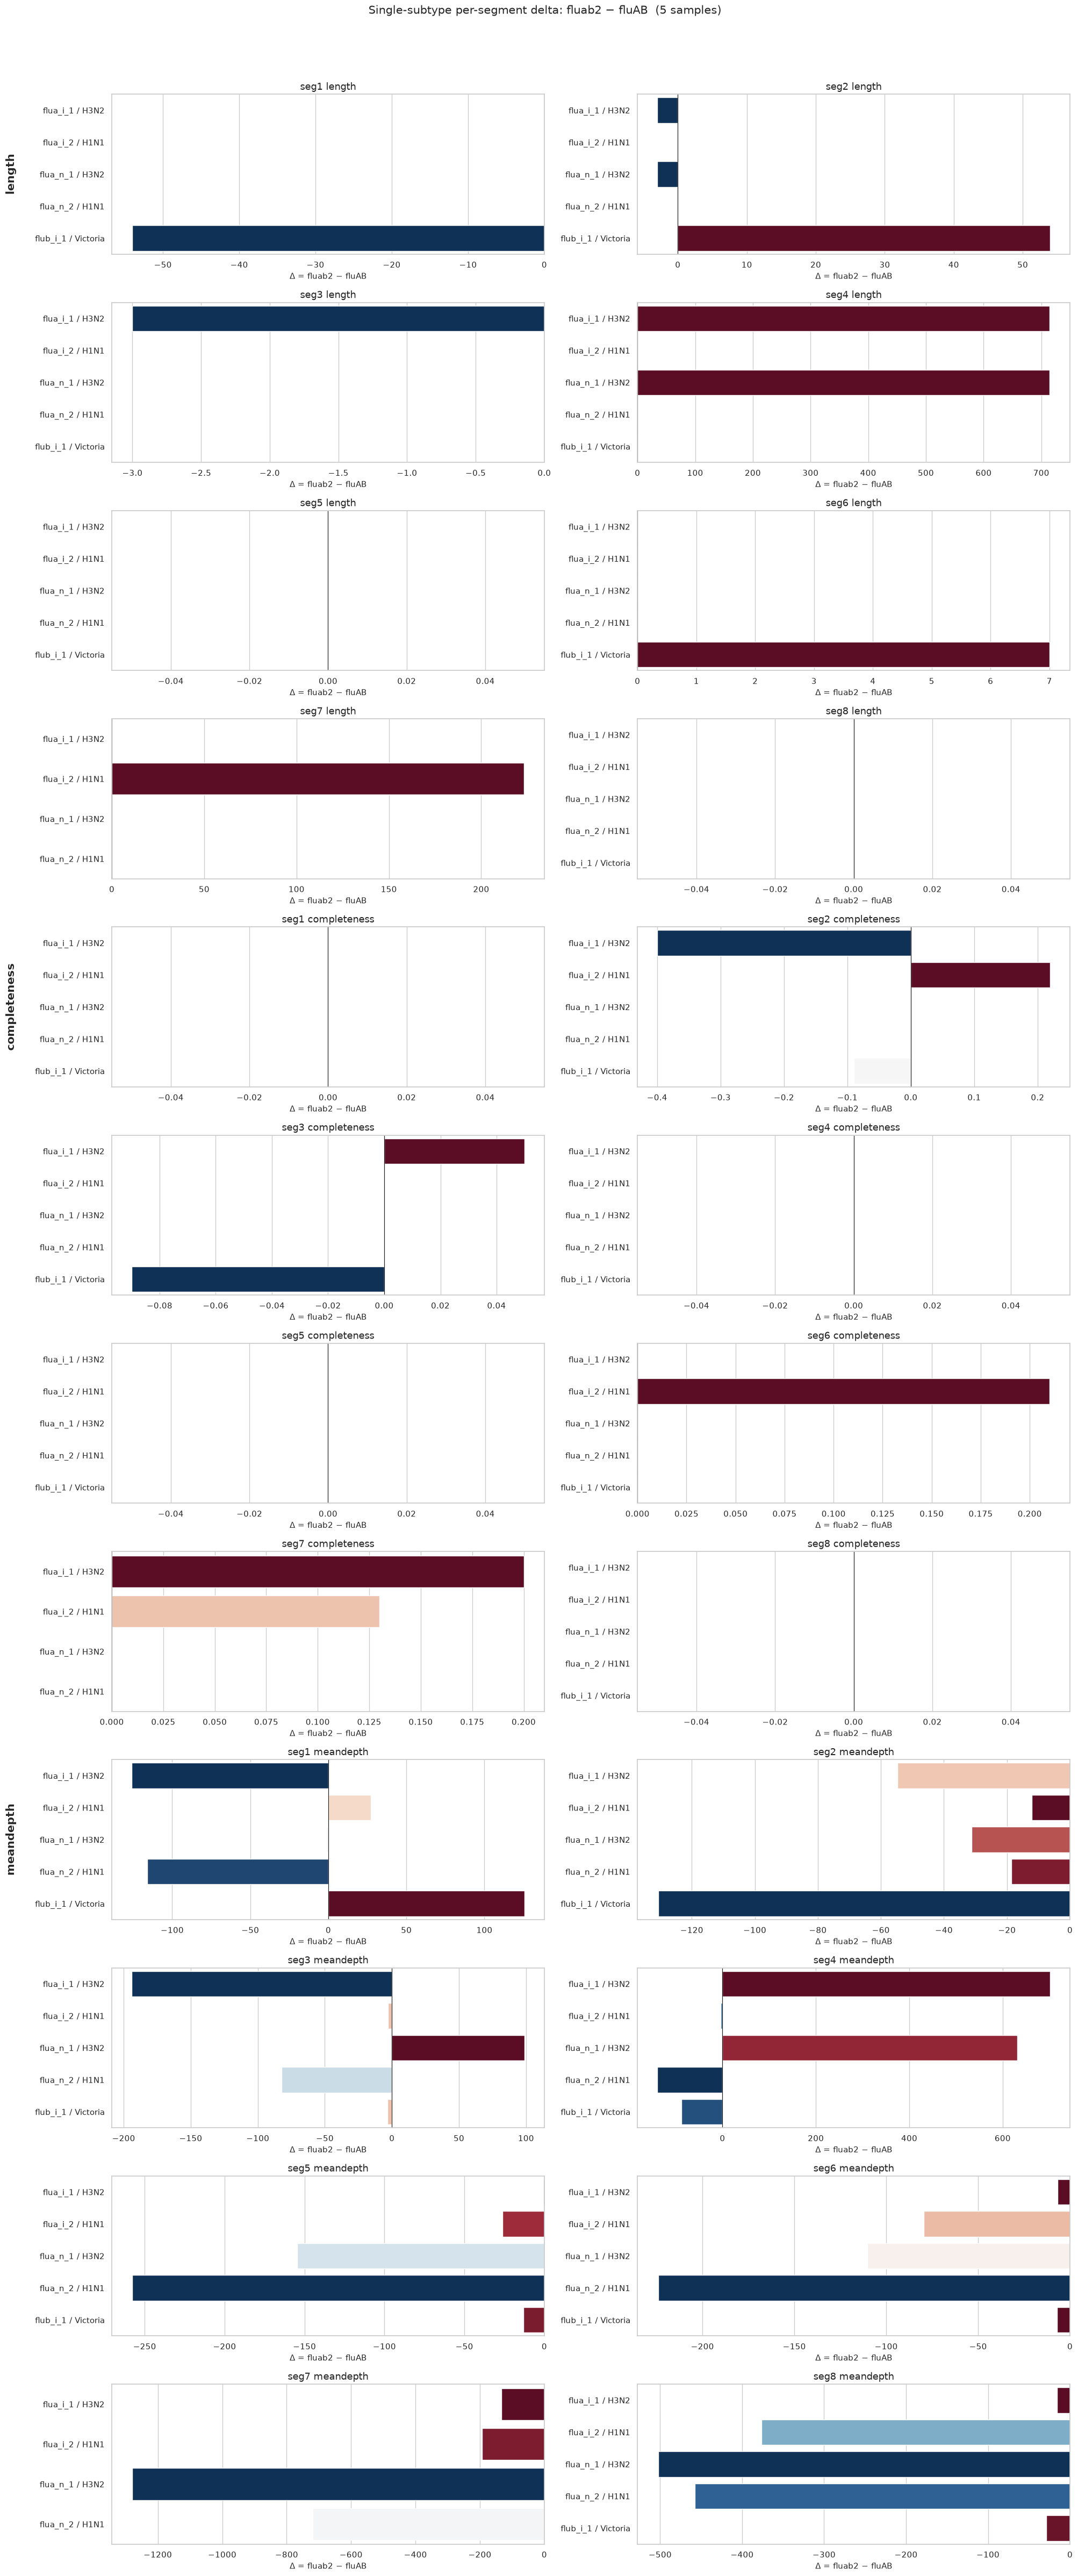

In [19]:
%matplotlib inline

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

MASTER_KEY = ["sample", "ref_subtype"]
SEGMENTS = ("1", "2", "3", "4", "5", "6", "7", "8")
SEGMENT_METRICS = ["length", "completeness", "meandepth"]


# ============================================================
# Non-co-infection helpers
# ============================================================

def find_single_subtype_samples(m1, m2, key=MASTER_KEY):
    """
    Return the set of sample names that have exactly one
    (sample, ref_subtype) row in both frames.
    """
    def per_sample_counts(df):
        if "sample" not in df.columns:
            return {}
        return df["sample"].astype(str).value_counts().to_dict()

    counts1 = per_sample_counts(m1)
    counts2 = per_sample_counts(m2)
    samples = set(counts1) | set(counts2)

    return {s for s in samples if counts1.get(s, 0) == 1 and counts2.get(s, 0) == 1}


def subset_single_subtype(df, samples):
    """Keep only rows whose sample is in `samples`."""
    if "sample" not in df.columns:
        return df.iloc[0:0]
    return df[df["sample"].astype(str).isin(samples)].copy()


def _key_order(m1, m2, key=MASTER_KEY):
    """Sorted compound keys from both frames."""
    keys = set()
    for df in (m1, m2):
        if not {"sample", "ref_subtype"}.issubset(df.columns):
            continue
        for s, r in zip(df["sample"].astype(str), df["ref_subtype"].astype(str)):
            keys.add(f"{s} / {r}")

    def sort_key(k):
        sample, _, ref = k.partition(" / ")
        return (sample, ref)

    return sorted(keys, key=sort_key)


def _prep_rows(df, source, segments, metrics, key):
    cols = [c for c in key if c in df.columns]
    for seg in segments:
        for met in metrics:
            col = f"seg{seg}_{met}"
            if col in df.columns:
                cols.append(col)

    d = df[cols].copy()
    d = d.rename(columns={key[0]: "sample", key[1]: "ref_subtype"})
    d["key"] = d["sample"].fillna("NA") + " / " + d["ref_subtype"].fillna("NA")
    d["source"] = source
    return d


# ============================================================
# Single-subtype coverage plot
# ============================================================

def plot_single_subtype_coverage(
    m1, m2, name1="fluAB", name2="fluab2",
    segments=SEGMENTS, metrics=SEGMENT_METRICS,
    key=MASTER_KEY, n_cols=2,
):
    """
    Same layout as plot_segment_coverage, restricted to
    samples with exactly one (sample, ref_subtype) row
    (i.e. not co-infected).

    Each x-tick is one sample / ref_subtype, so the bars are
    one pair per sample — no co-infection co-variates.
    """
    single = find_single_subtype_samples(m1, m2, key)
    if not single:
        print("No single-subtype samples found in either frame.")
        return None

    m1 = subset_single_subtype(m1, single)
    m2 = subset_single_subtype(m2, single)

    palette = {name1: "#4c72b0", name2: "#dd8452"}
    key_order = _key_order(m1, m2, key)

    long = pd.concat(
        [
            _prep_rows(m1, name1, segments, metrics, key),
            _prep_rows(m2, name2, segments, metrics, key),
        ],
        ignore_index=True,
    )
    long = long.melt(
        id_vars=["key", "source"],
        value_vars=[
            f"seg{seg}_{met}"
            for seg in segments for met in metrics
            if f"seg{seg}_{met}" in long.columns
        ],
        var_name="column", value_name="value",
    )
    parts = long["column"].str.extract(r"^seg(?P<seg>\d+)_(?P<met>.+)$")
    long = pd.concat([long, parts], axis=1)
    long["value"] = pd.to_numeric(long["value"], errors="coerce")
    long = long.dropna(subset=["value"])

    n_rows_per_metric = (len(segments) + n_cols - 1) // n_cols
    total_rows = n_rows_per_metric * len(metrics)

    fig, axes = plt.subplots(
        total_rows, n_cols,
        figsize=(10 * n_cols, 4 * n_rows_per_metric * len(metrics)),
        squeeze=False,
    )

    for met_idx, met in enumerate(metrics):
        for seg_idx, seg in enumerate(segments):
            row = met_idx * n_rows_per_metric + (seg_idx // n_cols)
            col = seg_idx % n_cols
            ax = axes[row][col]
            sub = long[(long["seg"] == seg) & (long["met"] == met)].copy()

            if sub.empty:
                ax.set_title(f"seg{seg} {met} (no data)", fontsize=13)
                ax.set_xticks([]); ax.set_yticks([])
                continue

            present = set(sub["key"].unique())
            order = [k for k in key_order if k in present]

            sns.barplot(
                data=sub, x="key", y="value", hue="source",
                palette=palette, order=order, ax=ax,
            )
            ax.set_title(f"seg{seg} {met}", fontsize=13)
            ax.set_xlabel("")
            ax.set_ylabel("", fontsize=11)
            ax.tick_params(axis="x", rotation=90, labelsize=11)
            ax.tick_params(axis="y", labelsize=11)

            leg = ax.get_legend()
            if leg is not None:
                leg.remove()

    for ax in list(axes.flat)[len(segments) * len(metrics):]:
        ax.set_visible(False)

    for met_idx, met in enumerate(metrics):
        row = met_idx * n_rows_per_metric
        axes[row][0].annotate(
            met, xy=(-0.22, 0.5), xycoords="axes fraction",
            fontsize=15, fontweight="bold", rotation=90,
            va="center", ha="right",
        )

    handles, labels = axes[0][0].get_legend_handles_labels()
    if handles:
        fig.legend(
            handles, labels, loc="upper right",
            title="pipeline", ncol=2, frameon=True, fontsize=13,
            title_fontsize=13,
        )

    fig.suptitle(
        f"Single-subtype per-segment coverage: {name1} vs {name2}  "
        f"({len(single)} samples)",
        fontsize=15, y=0.998,
    )
    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()
    return fig


# ============================================================
# Single-subtype delta plot
# ============================================================

def plot_single_subtype_delta(
    m1, m2, name1="fluAB", name2="fluab2",
    segments=SEGMENTS, metrics=SEGMENT_METRICS,
    key=MASTER_KEY, n_cols=2,
):
    """
    Signed delta (name2 − name1) per (sample, ref_subtype),
    restricted to samples with exactly one row.
    """
    single = find_single_subtype_samples(m1, m2, key)
    if not single:
        print("No single-subtype samples found in either frame.")
        return None

    m1 = subset_single_subtype(m1, single)
    m2 = subset_single_subtype(m2, single)

    key_order = _key_order(m1, m2, key)

    def prep(df):
        cols = [c for c in key if c in df.columns]
        for seg in segments:
            for met in metrics:
                col = f"seg{seg}_{met}"
                if col in df.columns:
                    cols.append(col)
        d = df[cols].copy()
        d = d.rename(columns={key[0]: "sample", key[1]: "ref_subtype"})
        d["key"] = d["sample"].fillna("NA") + " / " + d["ref_subtype"].fillna("NA")
        return d.set_index("key")

    a, b = prep(m1), prep(m2)
    common = a.index.intersection(b.index)

    n_rows_per_metric = (len(segments) + n_cols - 1) // n_cols
    total_rows = n_rows_per_metric * len(metrics)

    fig, axes = plt.subplots(
        total_rows, n_cols,
        figsize=(10 * n_cols, 4 * n_rows_per_metric * len(metrics)),
        squeeze=False,
    )

    for met_idx, met in enumerate(metrics):
        for seg_idx, seg in enumerate(segments):
            row = met_idx * n_rows_per_metric + (seg_idx // n_cols)
            col = seg_idx % n_cols
            ax = axes[row][col]
            column = f"seg{seg}_{met}"

            if column not in a.columns or column not in b.columns:
                ax.set_title(f"seg{seg} {met} (missing)", fontsize=13)
                ax.set_xticks([]); ax.set_yticks([])
                continue

            av = pd.to_numeric(a.loc[common, column], errors="coerce")
            bv = pd.to_numeric(b.loc[common, column], errors="coerce")
            delta = (bv - av).dropna()
            if delta.empty:
                ax.set_title(f"seg{seg} {met} (no data)", fontsize=13)
                continue

            present = set(delta.index)
            order = [k for k in key_order if k in present]

            sub = pd.DataFrame({
                "key": delta.index,
                "delta": delta.values,
            })

            sns.barplot(
                data=sub, x="delta", y="key",
                hue="delta", palette="RdBu_r", dodge=False,
                order=order, ax=ax,
            )
            ax.axvline(0, color="k", linewidth=0.8)
            ax.set_title(f"seg{seg} {met}", fontsize=13)
            ax.set_xlabel(f"Δ = {name2} − {name1}", fontsize=11)
            ax.set_ylabel("", fontsize=11)
            ax.tick_params(axis="x", labelsize=11)
            ax.tick_params(axis="y", labelsize=11)
            ax.legend().remove()

    for ax in list(axes.flat)[len(segments) * len(metrics):]:
        ax.set_visible(False)

    for met_idx, met in enumerate(metrics):
        row = met_idx * n_rows_per_metric
        axes[row][0].annotate(
            met, xy=(-0.22, 0.5), xycoords="axes fraction",
            fontsize=15, fontweight="bold", rotation=90,
            va="center", ha="right",
        )

    fig.suptitle(
        f"Single-subtype per-segment delta: {name2} − {name1}  "
        f"({len(single)} samples)",
        fontsize=15, y=0.998,
    )
    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()
    return fig


# ============================================================
# Render
# ============================================================

fig_ss_cov = plot_single_subtype_coverage(fluAB_df, fluab2_df)
fig_ss_delta = plot_single_subtype_delta(fluAB_df, fluab2_df)

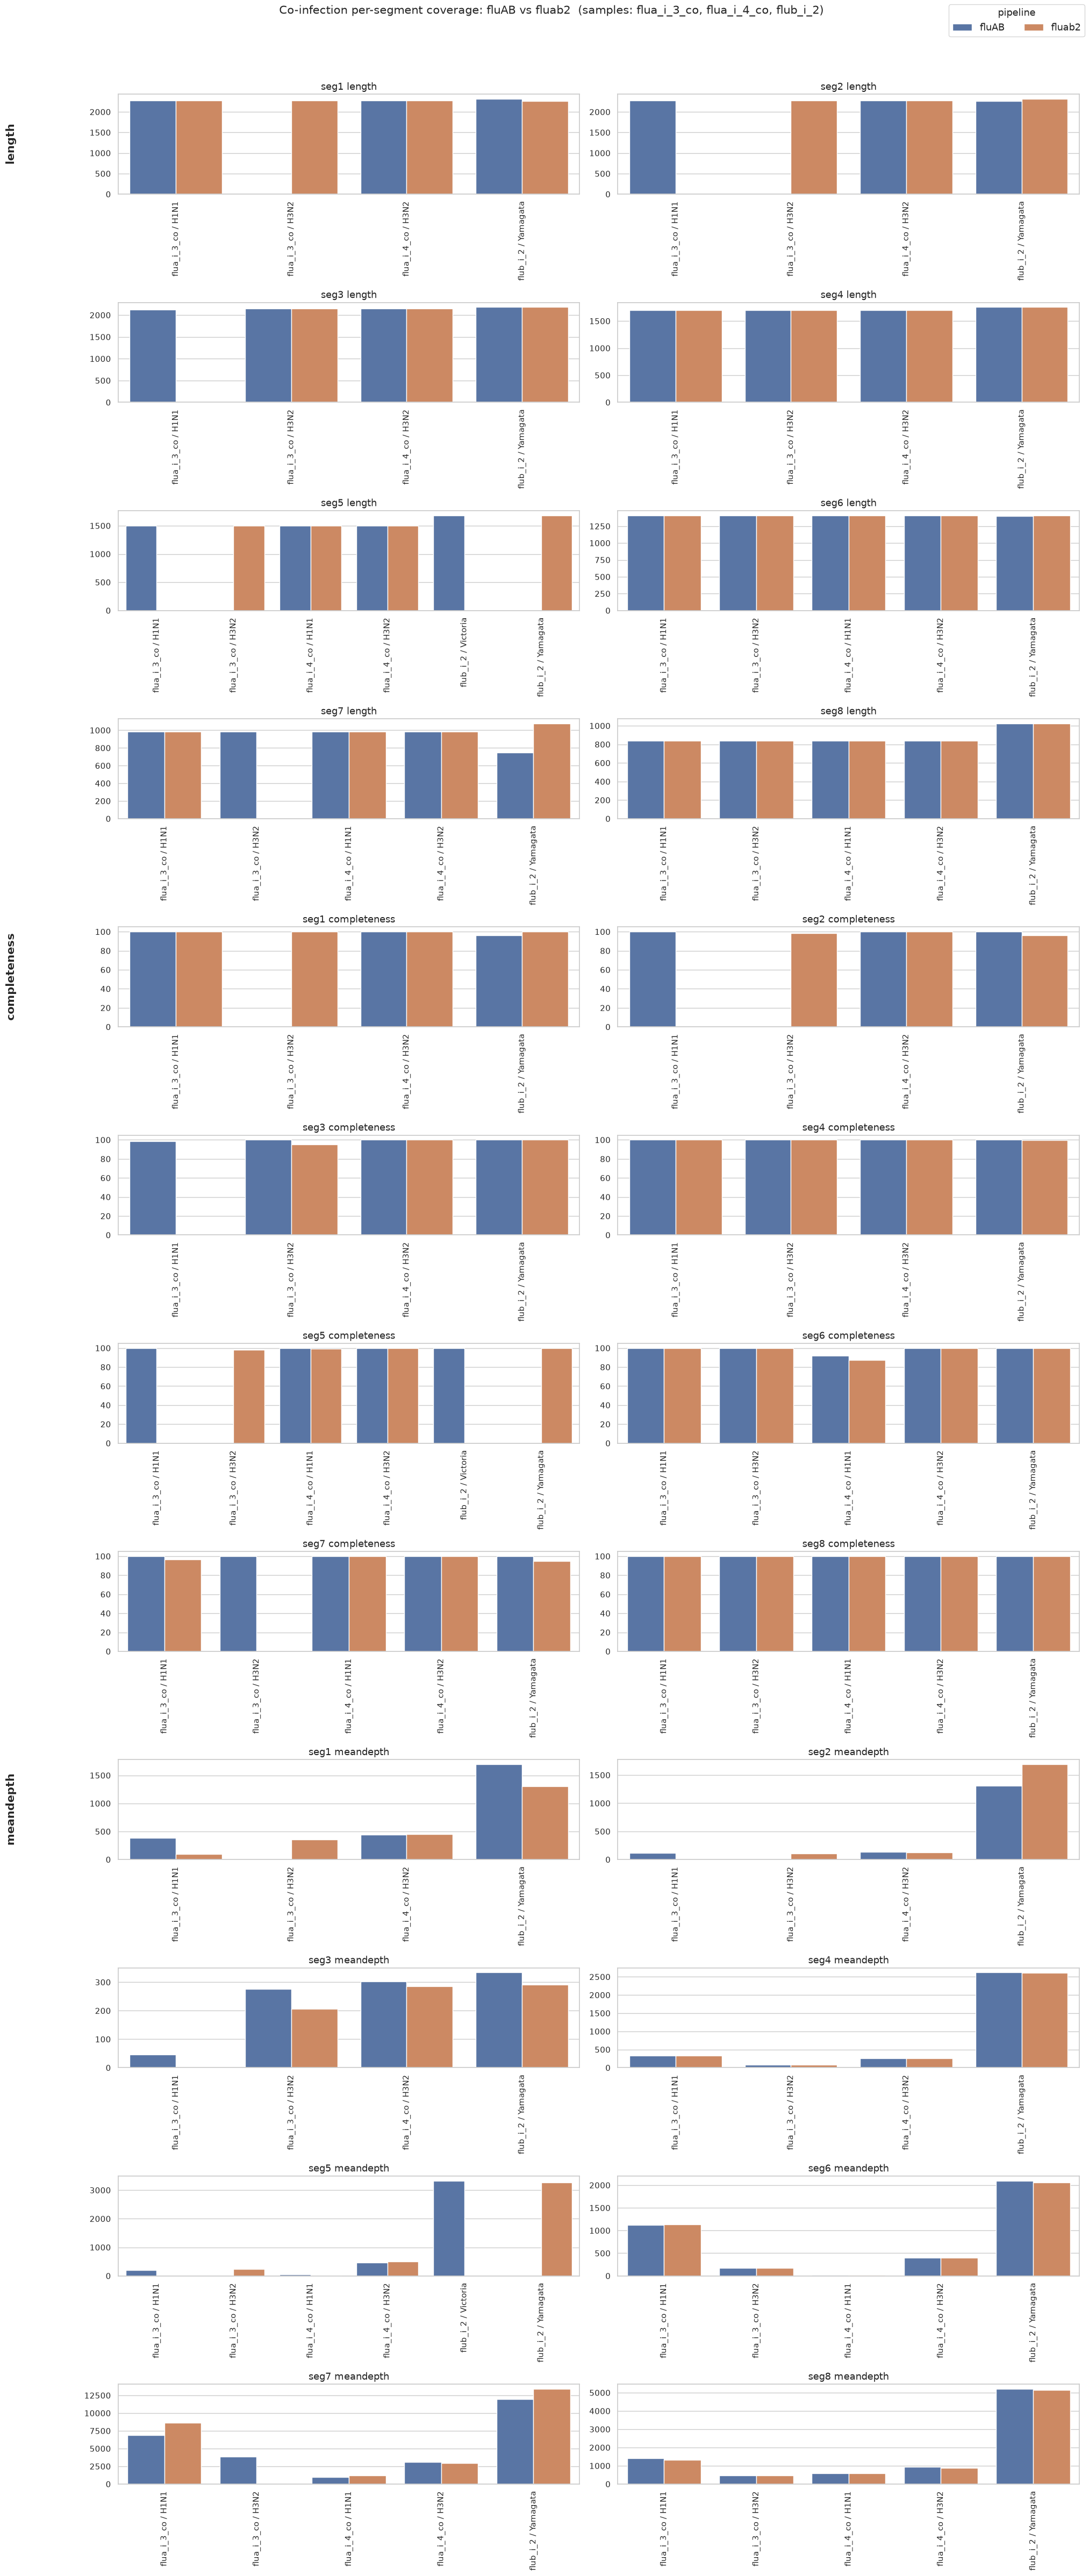

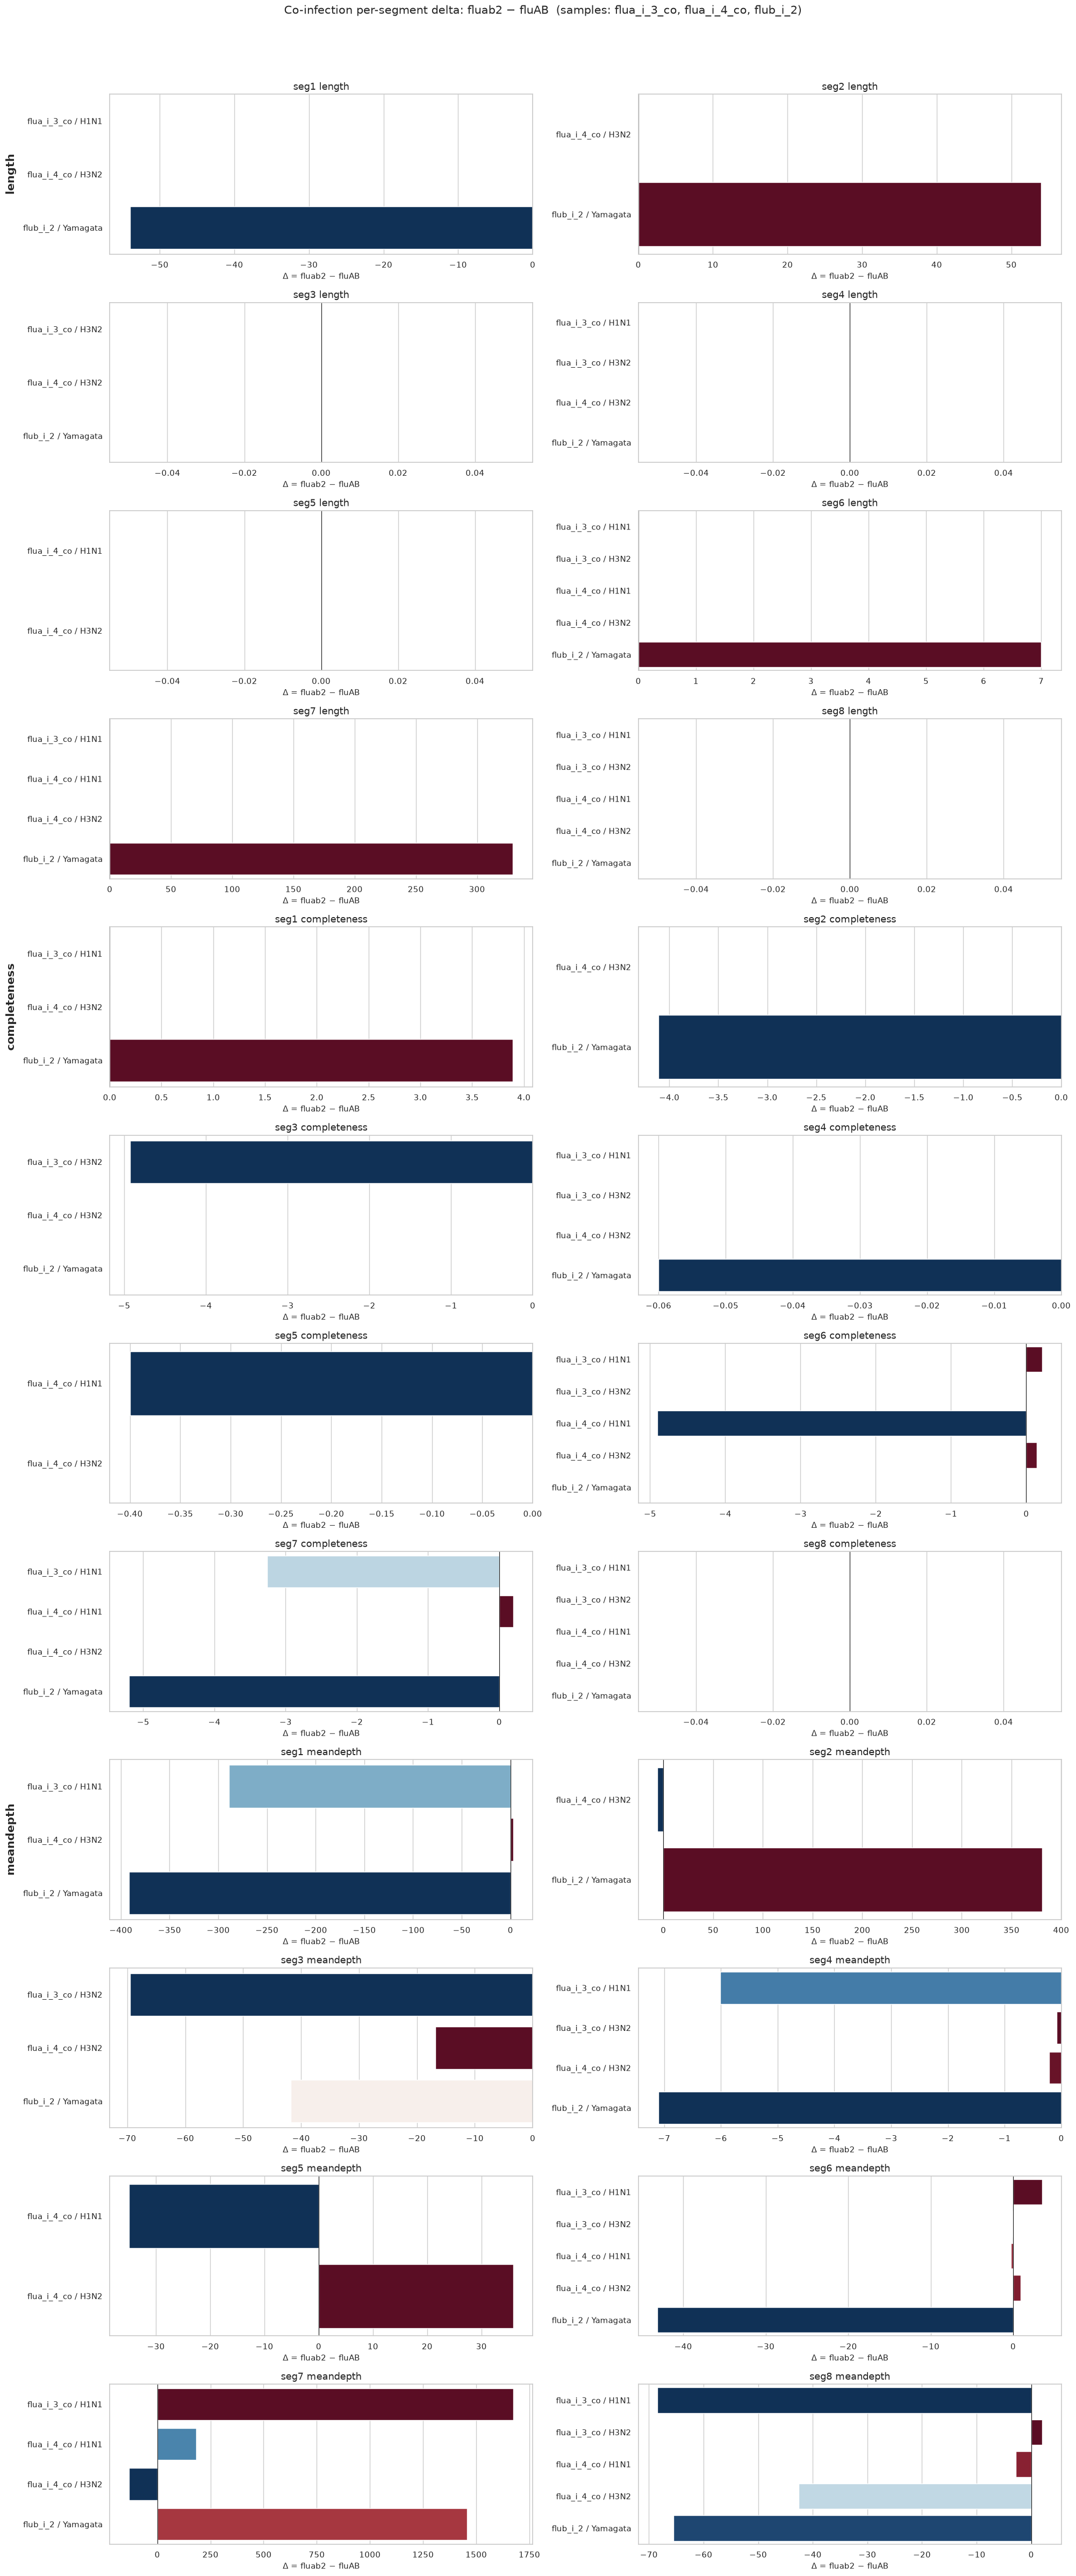

In [20]:
%matplotlib inline

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

MASTER_KEY = ["sample", "ref_subtype"]
SEGMENTS = ("1", "2", "3", "4", "5", "6", "7", "8")
SEGMENT_METRICS = ["length", "completeness", "meandepth"]


# ============================================================
# Co-infection helpers
# ============================================================

def find_coinfected_samples(m1, m2, key=MASTER_KEY):
    """
    Return the set of sample names that have more than one
    (sample, ref_subtype) row in either frame.
    """
    def per_sample_counts(df):
        if "sample" not in df.columns:
            return {}
        return df["sample"].astype(str).value_counts().to_dict()

    counts1 = per_sample_counts(m1)
    counts2 = per_sample_counts(m2)
    samples = set(counts1) | set(counts2)

    return {s for s in samples if counts1.get(s, 0) > 1 or counts2.get(s, 0) > 1}


def subset_coinfected(df, coinfected):
    """Keep only rows whose sample is in `coinfected`."""
    if "sample" not in df.columns:
        return df.iloc[0:0]
    return df[df["sample"].astype(str).isin(coinfected)].copy()


def _key_order(m1, m2, key=MASTER_KEY):
    """Sorted compound keys from both frames."""
    keys = set()
    for df in (m1, m2):
        if not {"sample", "ref_subtype"}.issubset(df.columns):
            continue
        for s, r in zip(df["sample"].astype(str), df["ref_subtype"].astype(str)):
            keys.add(f"{s} / {r}")

    def sort_key(k):
        sample, _, ref = k.partition(" / ")
        return (sample, ref)

    return sorted(keys, key=sort_key)


def _prep_rows(df, source, segments, metrics, key):
    cols = [c for c in key if c in df.columns]
    for seg in segments:
        for met in metrics:
            col = f"seg{seg}_{met}"
            if col in df.columns:
                cols.append(col)

    d = df[cols].copy()
    d = d.rename(columns={key[0]: "sample", key[1]: "ref_subtype"})
    d["key"] = d["sample"].fillna("NA") + " / " + d["ref_subtype"].fillna("NA")
    d["source"] = source
    return d


# ============================================================
# Coinfection coverage plot
# ============================================================

def plot_coinfection_coverage(
    m1, m2, name1="fluAB", name2="fluab2",
    segments=SEGMENTS, metrics=SEGMENT_METRICS,
    key=MASTER_KEY, n_cols=2,
):
    """
    Same layout as plot_segment_coverage, restricted to
    co-infected samples (those with more than one
    (sample, ref_subtype) row).

    Co-infections carry one bar group per (sample / ref_subtype),
    so a sample like flua_i_3_co appears twice on the x-axis —
    once per subtype — and both rows are evaluated independently.
    """
    coinfected = find_coinfected_samples(m1, m2, key)
    if not coinfected:
        print("No co-infected samples found in either frame.")
        return None

    m1 = subset_coinfected(m1, coinfected)
    m2 = subset_coinfected(m2, coinfected)

    palette = {name1: "#4c72b0", name2: "#dd8452"}
    key_order = _key_order(m1, m2, key)

    long = pd.concat(
        [
            _prep_rows(m1, name1, segments, metrics, key),
            _prep_rows(m2, name2, segments, metrics, key),
        ],
        ignore_index=True,
    )
    long = long.melt(
        id_vars=["key", "source"],
        value_vars=[
            f"seg{seg}_{met}"
            for seg in segments for met in metrics
            if f"seg{seg}_{met}" in long.columns
        ],
        var_name="column", value_name="value",
    )
    parts = long["column"].str.extract(r"^seg(?P<seg>\d+)_(?P<met>.+)$")
    long = pd.concat([long, parts], axis=1)
    long["value"] = pd.to_numeric(long["value"], errors="coerce")
    long = long.dropna(subset=["value"])

    n_rows_per_metric = (len(segments) + n_cols - 1) // n_cols
    total_rows = n_rows_per_metric * len(metrics)

    fig, axes = plt.subplots(
        total_rows, n_cols,
        figsize=(10 * n_cols, 4 * n_rows_per_metric * len(metrics)),
        squeeze=False,
    )

    for met_idx, met in enumerate(metrics):
        for seg_idx, seg in enumerate(segments):
            row = met_idx * n_rows_per_metric + (seg_idx // n_cols)
            col = seg_idx % n_cols
            ax = axes[row][col]
            sub = long[(long["seg"] == seg) & (long["met"] == met)].copy()

            if sub.empty:
                ax.set_title(f"seg{seg} {met} (no data)", fontsize=13)
                ax.set_xticks([]); ax.set_yticks([])
                continue

            present = set(sub["key"].unique())
            order = [k for k in key_order if k in present]

            sns.barplot(
                data=sub, x="key", y="value", hue="source",
                palette=palette, order=order, ax=ax,
            )
            ax.set_title(f"seg{seg} {met}", fontsize=13)
            ax.set_xlabel("")
            ax.set_ylabel("", fontsize=11)
            ax.tick_params(axis="x", rotation=90, labelsize=11)
            ax.tick_params(axis="y", labelsize=11)

            leg = ax.get_legend()
            if leg is not None:
                leg.remove()

    for ax in list(axes.flat)[len(segments) * len(metrics):]:
        ax.set_visible(False)

    for met_idx, met in enumerate(metrics):
        row = met_idx * n_rows_per_metric
        axes[row][0].annotate(
            met, xy=(-0.22, 0.5), xycoords="axes fraction",
            fontsize=15, fontweight="bold", rotation=90,
            va="center", ha="right",
        )

    handles, labels = axes[0][0].get_legend_handles_labels()
    if handles:
        fig.legend(
            handles, labels, loc="upper right",
            title="pipeline", ncol=2, frameon=True, fontsize=13,
            title_fontsize=13,
        )

    fig.suptitle(
        f"Co-infection per-segment coverage: {name1} vs {name2}  "
        f"(samples: {', '.join(sorted(coinfected))})",
        fontsize=15, y=0.998,
    )
    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()
    return fig


# ============================================================
# Coinfection delta plot
# ============================================================

def plot_coinfection_delta(
    m1, m2, name1="fluAB", name2="fluab2",
    segments=SEGMENTS, metrics=SEGMENT_METRICS,
    key=MASTER_KEY, n_cols=2,
):
    """
    Signed delta (name2 − name1) per (sample, ref_subtype),
    restricted to co-infected samples.
    """
    coinfected = find_coinfected_samples(m1, m2, key)
    if not coinfected:
        print("No co-infected samples found in either frame.")
        return None

    m1 = subset_coinfected(m1, coinfected)
    m2 = subset_coinfected(m2, coinfected)

    key_order = _key_order(m1, m2, key)

    def prep(df):
        cols = [c for c in key if c in df.columns]
        for seg in segments:
            for met in metrics:
                col = f"seg{seg}_{met}"
                if col in df.columns:
                    cols.append(col)
        d = df[cols].copy()
        d = d.rename(columns={key[0]: "sample", key[1]: "ref_subtype"})
        d["key"] = d["sample"].fillna("NA") + " / " + d["ref_subtype"].fillna("NA")
        return d.set_index("key")

    a, b = prep(m1), prep(m2)
    common = a.index.intersection(b.index)

    n_rows_per_metric = (len(segments) + n_cols - 1) // n_cols
    total_rows = n_rows_per_metric * len(metrics)

    fig, axes = plt.subplots(
        total_rows, n_cols,
        figsize=(10 * n_cols, 4 * n_rows_per_metric * len(metrics)),
        squeeze=False,
    )

    for met_idx, met in enumerate(metrics):
        for seg_idx, seg in enumerate(segments):
            row = met_idx * n_rows_per_metric + (seg_idx // n_cols)
            col = seg_idx % n_cols
            ax = axes[row][col]
            column = f"seg{seg}_{met}"

            if column not in a.columns or column not in b.columns:
                ax.set_title(f"seg{seg} {met} (missing)", fontsize=13)
                ax.set_xticks([]); ax.set_yticks([])
                continue

            av = pd.to_numeric(a.loc[common, column], errors="coerce")
            bv = pd.to_numeric(b.loc[common, column], errors="coerce")
            delta = (bv - av).dropna()
            if delta.empty:
                ax.set_title(f"seg{seg} {met} (no data)", fontsize=13)
                continue

            present = set(delta.index)
            order = [k for k in key_order if k in present]

            sub = pd.DataFrame({
                "key": delta.index,
                "delta": delta.values,
            })

            sns.barplot(
                data=sub, x="delta", y="key",
                hue="delta", palette="RdBu_r", dodge=False,
                order=order, ax=ax,
            )
            ax.axvline(0, color="k", linewidth=0.8)
            ax.set_title(f"seg{seg} {met}", fontsize=13)
            ax.set_xlabel(f"Δ = {name2} − {name1}", fontsize=11)
            ax.set_ylabel("", fontsize=11)
            ax.tick_params(axis="x", labelsize=11)
            ax.tick_params(axis="y", labelsize=11)
            ax.legend().remove()

    for ax in list(axes.flat)[len(segments) * len(metrics):]:
        ax.set_visible(False)

    for met_idx, met in enumerate(metrics):
        row = met_idx * n_rows_per_metric
        axes[row][0].annotate(
            met, xy=(-0.22, 0.5), xycoords="axes fraction",
            fontsize=15, fontweight="bold", rotation=90,
            va="center", ha="right",
        )

    fig.suptitle(
        f"Co-infection per-segment delta: {name2} − {name1}  "
        f"(samples: {', '.join(sorted(coinfected))})",
        fontsize=15, y=0.998,
    )
    plt.tight_layout(rect=[0, 0, 1, 0.98])
    plt.show()
    return fig


# ============================================================
# Render
# ============================================================

fig_co_cov = plot_coinfection_coverage(fluAB_df, fluab2_df)
fig_co_delta = plot_coinfection_delta(fluAB_df, fluab2_df)

# typing comparison

In [21]:
import pandas as pd

TYPING_SEGMENTS = ("4", "6", "7")
TYPING_METRICS = ["typing_pident", "typing_qcov"]

for name in ["fluAB", "fluab2"]:
    if name not in frames:
        print(f"{name}: not in frames")
        continue
    df = frames[name]
    print(f"=== {name} ===")
    print(f"  shape: {df.shape}")
    for seg in TYPING_SEGMENTS:
        for met in TYPING_METRICS:
            col = f"seg{seg}_{met}"
            if col in df.columns:
                n = pd.to_numeric(df[col], errors="coerce").notna().sum()
                print(f"  {col:24s}  present  numeric={n}/{len(df)}")
            else:
                print(f"  {col:24s}  MISSING")
    print()

fluAB: not in frames
=== fluab2 ===
  shape: (10, 82)
  seg4_typing_pident        present  numeric=9/10
  seg4_typing_qcov          present  numeric=9/10
  seg6_typing_pident        present  numeric=8/10
  seg6_typing_qcov          present  numeric=8/10
  seg7_typing_pident        present  numeric=7/10
  seg7_typing_qcov          present  numeric=7/10



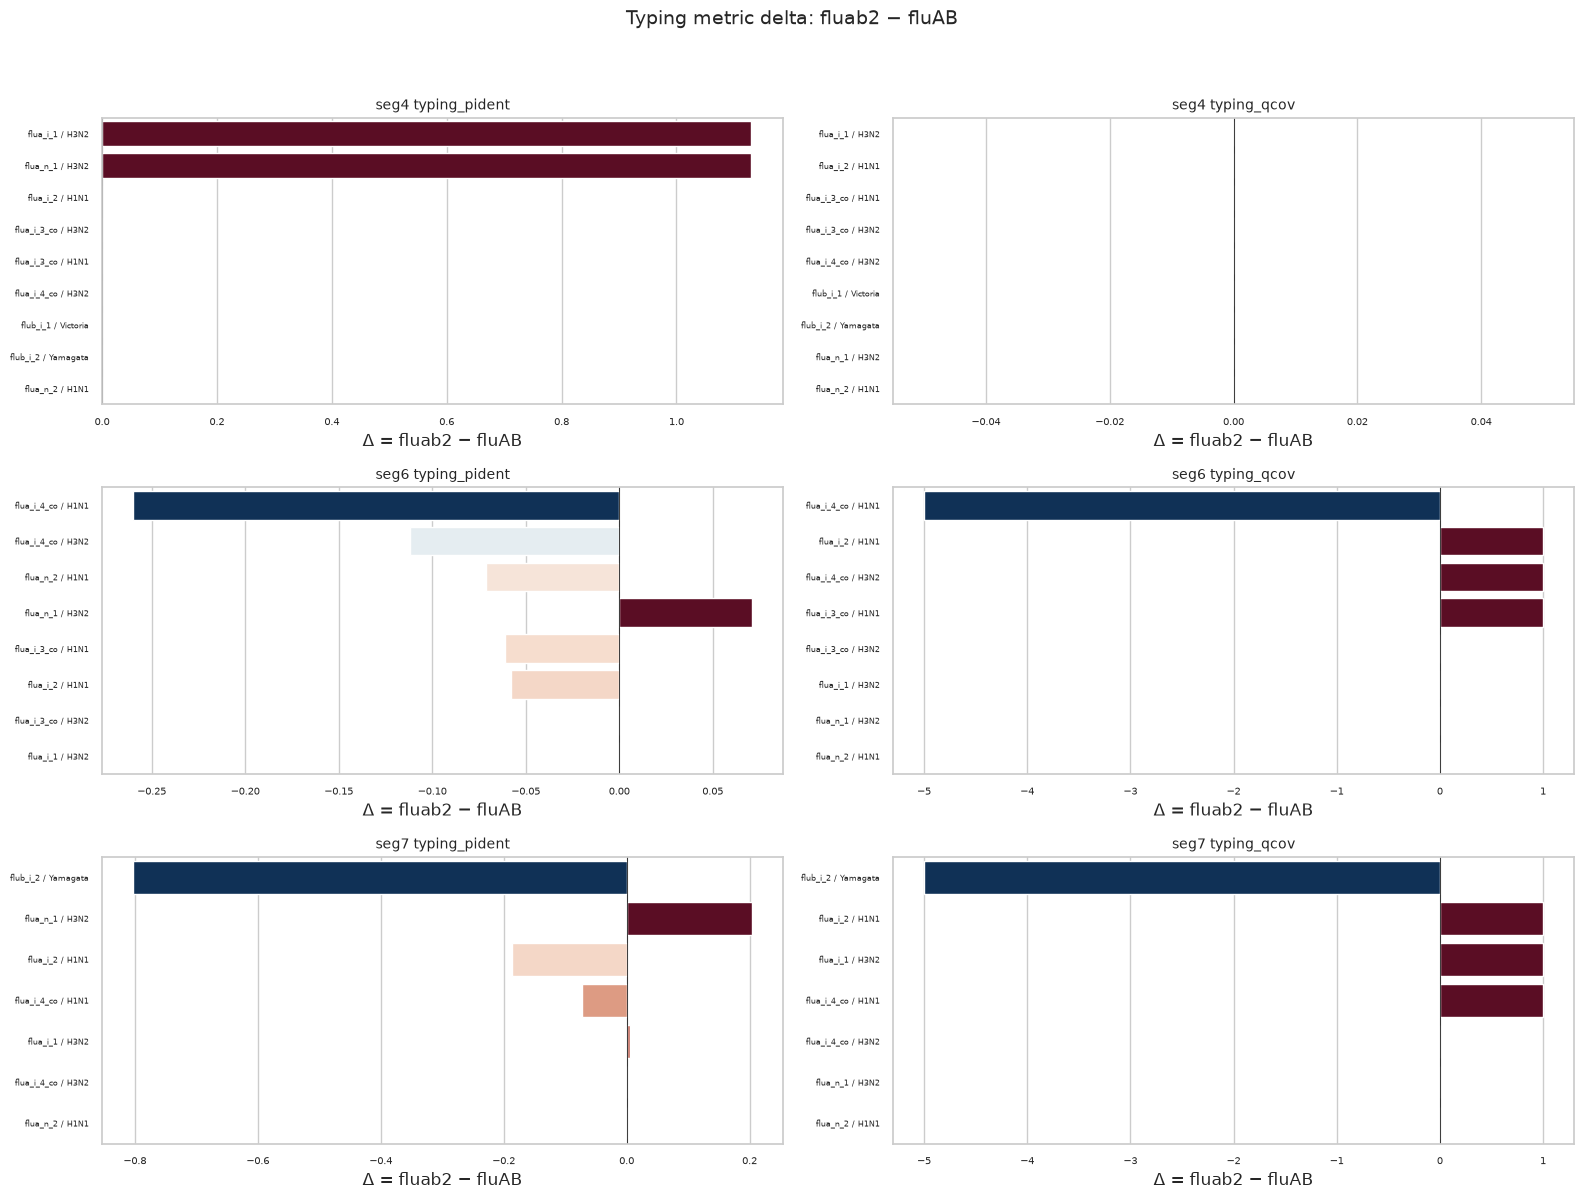

In [22]:
def plot_typing_delta(m1, m2, name1="fluAB", name2="fluab2",
                      segments=TYPING_SEGMENTS, metrics=TYPING_METRICS,
                      key=MASTER_KEY):
    def prep(df):
        keep = [c for c in key if c in df.columns]
        for seg in segments:
            for met in metrics:
                col = f"seg{seg}_{met}"
                if col in df.columns:
                    keep.append(col)
        d = df[keep].copy()
        d = d.rename(columns={key[0]: "sample", key[1]: "ref_subtype"})
        d["key"] = d["sample"].fillna("NA") + " / " + d["ref_subtype"].fillna("NA")
        return d.set_index("key")

    a, b = prep(m1), prep(m2)
    common = a.index.intersection(b.index)

    n_rows, n_cols = len(segments), len(metrics)
    fig, axes = plt.subplots(n_rows, n_cols,
                             figsize=(8 * n_cols, 4 * n_rows),
                             squeeze=False)

    for row_idx, seg in enumerate(segments):
        for col_idx, met in enumerate(metrics):
            ax = axes[row_idx][col_idx]
            col = f"seg{seg}_{met}"

            if col not in a.columns or col not in b.columns:
                ax.set_title(f"seg{seg} {met} (missing)", fontsize=10)
                ax.set_xticks([]); ax.set_yticks([])
                continue

            av = pd.to_numeric(a.loc[common, col], errors="coerce")
            bv = pd.to_numeric(b.loc[common, col], errors="coerce")
            delta = (bv - av).dropna()
            if delta.empty:
                ax.set_title(f"seg{seg} {met} (no numeric data)", fontsize=10)
                ax.set_xticks([]); ax.set_yticks([])
                continue

            sub = pd.DataFrame({
                "key": delta.index,
                "delta": delta.values,
            }).sort_values("delta", key=abs, ascending=False)

            sns.barplot(data=sub, x="delta", y="key",
                        hue="delta", palette="RdBu_r", dodge=False, ax=ax)
            ax.axvline(0, color="k", linewidth=0.6)
            ax.set_title(f"seg{seg} {met}", fontsize=10)
            ax.set_xlabel(f"Δ = {name2} − {name1}")
            ax.set_ylabel("")
            ax.tick_params(axis="x", labelsize=7)
            ax.tick_params(axis="y", labelsize=6)
            ax.legend().remove()

    fig.suptitle(f"Typing metric delta: {name2} − {name1}",
                 fontsize=14, y=0.998)
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()
    return fig


fig_delta = plot_typing_delta(fluAB_df, fluab2_df)

Agreement per column: fluAB vs fluab2
                   column  keys  agree  disagree  pct_agree
predicted_type_or_lineage    11     11         0      100.0
               seg4_clade    11     11         0      100.0
    seg4_proposedSubclade    11     10         1       90.9
            seg4_subclade    11     11         0      100.0
               seg6_clade    11      2         9       18.2
    seg6_proposedSubclade    11      2         9       18.2
            seg6_subclade    11     11         0      100.0

Disagreements
               column                 key fluAB  fluab2
seg4_proposedSubclade flub_i_1 / Victoria C.5.6 C.5.6.1
           seg6_clade     flua_i_1 / H3N2    NA       B
           seg6_clade     flua_i_2 / H1N1    NA   C.5.2
           seg6_clade  flua_i_3_co / H1N1    NA C.5.1.1
           seg6_clade  flua_i_3_co / H3N2    NA A.2.2.2
           seg6_clade  flua_i_4_co / H1N1    NA       D
           seg6_clade  flua_i_4_co / H3N2    NA   B.4.2
           seg6_cla

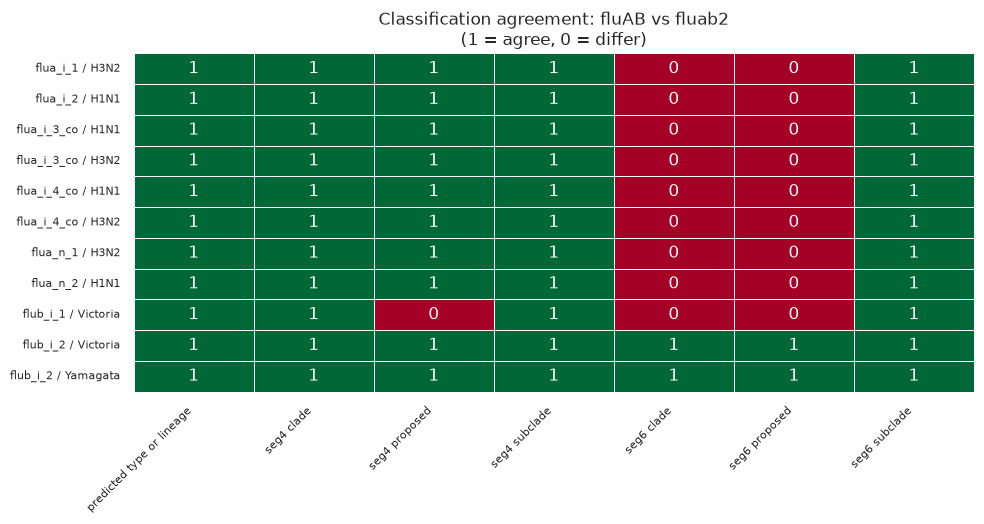

In [23]:
%matplotlib inline

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

MASTER_KEY = ["sample", "ref_subtype"]

LINEAGE_COLUMNS = [
    "predicted_type_or_lineage",
    "seg4_clade", "seg4_proposedSubclade", "seg4_subclade",
    "seg6_clade", "seg6_proposedSubclade", "seg6_subclade",
]


def compare_lineage(m1, m2, name1="fluAB", name2="fluab2",
                    columns=LINEAGE_COLUMNS, key=MASTER_KEY):
    """
    Compare clade / subclade / lineage columns between two
    pipelines, keeping every (sample, ref_subtype) row.

    Outputs:
        1. A printed agreement table per column.
        2. A printed table of disagreements per column.
        3. A heatmap: one row per key, one column per
           classification field, green = agree, red = differ.

    Returns:
        side : DataFrame with both pipelines' values and an
               `agree` flag per column.
    """

    def prep(df, source):
        cols = [c for c in key if c in df.columns]
        cols += [c for c in columns if c in df.columns and c not in cols]
        d = df[cols].copy()
        d = d.rename(columns={key[0]: "sample", key[1]: "ref_subtype"})
        d["key"] = (
            d["sample"].fillna("NA") + " / " + d["ref_subtype"].fillna("NA")
        )
        for c in columns:
            if c in d.columns:
                d[c] = d[c].fillna("NA").astype(str)
        d["source"] = source
        return d

    d1 = prep(m1, name1)
    d2 = prep(m2, name2)

    # Per-column agreement.
    print("=" * 60)
    print(f"Agreement per column: {name1} vs {name2}")
    print("=" * 60)

    summary_rows = []
    disagreements = []

    for col in columns:
        if col not in d1.columns or col not in d2.columns:
            print(f"  {col:28s}  MISSING from one or both frames")
            continue

        a = d1.set_index("key")[col]
        b = d2.set_index("key")[col]
        joined = pd.DataFrame({name1: a, name2: b}).fillna("NA")
        joined["agree"] = joined[name1] == joined[name2]

        n_total = len(joined)
        n_agree = int(joined["agree"].sum())
        n_disagree = n_total - n_agree

        summary_rows.append({
            "column": col,
            "keys": n_total,
            "agree": n_agree,
            "disagree": n_disagree,
            "pct_agree": (
                round(100 * n_agree / n_total, 1) if n_total else 0
            ),
        })

        if n_disagree:
            sub = joined.loc[~joined["agree"]].reset_index()
            sub = sub.rename(columns={"index": "key"})
            sub["column"] = col
            disagreements.append(sub[["column", "key", name1, name2]])

    if summary_rows:
        print(pd.DataFrame(summary_rows).to_string(index=False))
    print()

    if disagreements:
        print("=" * 60)
        print("Disagreements")
        print("=" * 60)
        print(pd.concat(disagreements, ignore_index=True).to_string(index=False))
        print()
    else:
        print("No disagreements across any classification column.\n")

    # Per-key × per-column agreement heatmap.
    keys = sorted(set(d1["key"]) | set(d2["key"]))
    matrix = pd.DataFrame(index=keys, columns=columns, dtype=float)

    for col in columns:
        if col not in d1.columns or col not in d2.columns:
            continue
        a = d1.set_index("key")[col].reindex(keys).fillna("NA")
        b = d2.set_index("key")[col].reindex(keys).fillna("NA")
        matrix[col] = (a == b).astype(float)

    if not matrix.empty:
        # Shorten column labels for readability.
        matrix.columns = [
            c.replace("proposedSubclade", "proposed").replace("_", " ")
            for c in matrix.columns
        ]

        fig, ax = plt.subplots(
            figsize=(max(6, 1.0 * len(matrix.columns) + 3),
                     max(3, 0.4 * len(matrix.index) + 1)),
        )
        sns.heatmap(
            matrix, cmap="RdYlGn", vmin=0, vmax=1,
            cbar=False, linewidths=0.5, linecolor="white",
            annot=True, fmt=".0f", ax=ax,
        )
        ax.set_xlabel("")
        ax.set_ylabel("")
        ax.set_title(
            f"Classification agreement: {name1} vs {name2}\n"
            f"(1 = agree, 0 = differ)"
        )
        plt.xticks(rotation=45, ha="right", fontsize=8)
        plt.yticks(fontsize=8)
        plt.tight_layout()
        plt.show()

    return {
        "summary": pd.DataFrame(summary_rows),
        "disagreements": (
            pd.concat(disagreements, ignore_index=True)
            if disagreements else pd.DataFrame()
        ),
    }


result = compare_lineage(fluAB_df, fluab2_df)

In [24]:
import pandas as pd

MASTER_KEY = ["sample", "ref_subtype"]

LINEAGE_COLUMNS = [
    "predicted_type_or_lineage",
    "seg4_clade", "seg4_proposedSubclade", "seg4_subclade",
    "seg6_clade", "seg6_proposedSubclade", "seg6_subclade",
]


def diff_table(m1, m2, columns=LINEAGE_COLUMNS, key=MASTER_KEY,
               name1="fluAB", name2="fluab2"):
    """
    One row per (sample, ref_subtype), one column per
    classification field.

    Each cell shows:
        "value"          both pipelines agree, non-NA
        "a → b"          pipelines differ (a = name1, b = name2)
        ""               both NA
    """

    def prep(df):
        cols = [c for c in key if c in df.columns]
        cols += [c for c in columns if c in df.columns and c not in cols]
        d = df[cols].copy()
        d = d.rename(columns={key[0]: "sample", key[1]: "ref_subtype"})
        d["key"] = d["sample"].fillna("NA") + " / " + d["ref_subtype"].fillna("NA")
        for c in columns:
            if c in d.columns:
                d[c] = d[c].fillna("NA").astype(str)
        return d.set_index("key")

    a, b = prep(m1), prep(m2)
    keys = sorted(set(a.index) | set(b.index))

    rows = []
    for k in keys:
        row = {"key": k}
        diffs = []
        for col in columns:
            av = a.loc[k, col] if (k in a.index and col in a.columns) else "NA"
            bv = b.loc[k, col] if (k in b.index and col in b.columns) else "NA"

            if av == bv:
                row[col] = "" if av == "NA" else av
            else:
                row[col] = f"{av} → {bv}"
                diffs.append(col)

        row["status"] = f"{len(diffs)} diff" if diffs else "same"
        rows.append(row)

    df = pd.DataFrame(rows).set_index("key")

    df = df.assign(
        n_diff=df["status"].str.extract(r"(\d+)").astype(float).fillna(0)
    ).sort_values("n_diff", ascending=False).drop(columns="n_diff")

    return df, name1, name2


table, name1, name2 = diff_table(fluAB_df, fluab2_df)

# ---- Direction note (visible once, above the table) ----

print("=" * 80)
print(f"Classification differences: {name1} vs {name2}")
print("=" * 80)
print(f"Arrow notation:  <{name1} value> → <{name2} value>")
print(f"  e.g. 'N1 → H1N1' means {name1} said N1 and {name2} said H1N1")
print(f"  blank cell = both pipelines say NA")
print(f"  plain value = both pipelines agree")
print("=" * 80)
print()

print(table.to_string())

Classification differences: fluAB vs fluab2
Arrow notation:  <fluAB value> → <fluab2 value>
  e.g. 'N1 → H1N1' means fluAB said N1 and fluab2 said H1N1
  blank cell = both pipelines say NA
  plain value = both pipelines agree

                    predicted_type_or_lineage seg4_clade seg4_proposedSubclade seg4_subclade    seg6_clade seg6_proposedSubclade seg6_subclade  status
key                                                                                                                                                   
flub_i_1 / Victoria                  Victoria    C.5.6.1       C.5.6 → C.5.6.1       C.5.6.1      NA → B.8              NA → B.8                3 diff
flua_i_2 / H1N1                          H1N1        D.1                   D.1           D.1    NA → C.5.2            NA → C.5.2                2 diff
flua_i_1 / H3N2                          H3N2        G.1                   G.1           G.1        NA → B                NA → B                2 diff
flua_i_3_co / H1N1